# Скоринговая модель прогнозирования дефолта

Исследовательский ноутбук Google Colab: анализ данных, подготовка признаков, валидация, эксперименты MLflow и создание модулей MLOps-проекта.

## Как читать ноутбук

Ячейки отражают ход разработки и восстановления среды Colab. Сохранены промежуточные ошибки запуска интерфейса MLflow и загрузки артефакта модели; далее показано успешное восстановление модели из резервной копии и совпадение прогнозов. Это история работы, а не проверенный сценарий «Выполнить всё» в новой среде.

Для воспроизведения итогового пайплайна и запуска API используйте инструкции в [README](../README.md). Сценарий демонстрации находится в [docs/demo.md](../docs/demo.md). Данные, обученные модели и исходные эксперименты восстанавливаются из DVC-хранилища или полной резервной копии.

Итог: `C=0.1`, порог `0.3`; тестовые метрики ROC-AUC `0.7613`, Precision `0.5392`, Recall `0.5026`, F1 `0.5203`.

После сохранения этого ноутбука Docker-образ был успешно собран и проверен в Windows: `/health` вернул готовность, прогноз на сохранённом примере совпал с Colab, отрицательный платёж был отклонён с HTTP 422. Результаты этой отдельной проверки описаны в README.


## 1. Загрузка данных, EDA и разбиение выборки


In [ ]:
from google.colab import files

uploaded = files.upload()


Saving archive.zip to archive.zip


In [ ]:
import zipfile
from pathlib import Path
import pandas as pd

# Создаём папку для исходных данных
raw_folder = Path("data/raw")
raw_folder.mkdir(parents=True, exist_ok=True)

# Достаём CSV-файл из архива
with zipfile.ZipFile("archive.zip", "r") as archive:
    archive.extract("UCI_Credit_Card.csv", path=raw_folder)

# Читаем таблицу и сохраняем её в переменной df
df = pd.read_csv(raw_folder / "UCI_Credit_Card.csv")

# Показываем размер таблицы и первые пять строк
print(f"Количество строк: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")

display(df.head())

Количество строк: 30000
Количество столбцов: 25


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   300

In [ ]:
print("Пропуски по столбцам:")
print(df.isna().sum())

print("\nКоличество полностью одинаковых строк:")
print(df.duplicated().sum())

print("\nВсе ID уникальны:")
print(df["ID"].is_unique)

Пропуски по столбцам:
ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64

Количество полностью одинаковых строк:
0

Все ID уникальны:
True


In [ ]:
# Название столбца с правильными ответами
target = "default.payment.next.month"

# Сколько клиентов относится к каждому классу
counts = df[target].value_counts().sort_index()

# Какая доля клиентов относится к каждому классу
percentages = df[target].value_counts(
    normalize=True
).sort_index() * 100

target_summary = pd.DataFrame({
    "Количество клиентов": counts,
    "Доля, %": percentages.round(2)
})

display(target_summary)

,Количество клиентов,"Доля, %"
default.payment.next.month,,
0,23364,77.88
1,6636,22.12


In [ ]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df[target]
)

print(f"Клиентов для обучения: {len(train_df)}")
print(f"Клиентов для итоговой проверки: {len(test_df)}")

print("\nДоля дефолтов в обучающей выборке:")
print(f"{train_df[target].mean():.2%}")

print("\nДоля дефолтов в тестовой выборке:")
print(f"{test_df[target].mean():.2%}")

Клиентов для обучения: 24000
Клиентов для итоговой проверки: 6000

Доля дефолтов в обучающей выборке:
22.12%

Доля дефолтов в тестовой выборке:
22.12%


In [ ]:
for column in ["EDUCATION", "MARRIAGE"]:
    print(f"\nПризнак: {column}")
    print(train_df[column].value_counts(dropna=False).sort_index())


Признак: EDUCATION
EDUCATION
0       12
1     8455
2    11256
3     3903
4       97
5      235
6       42
Name: count, dtype: int64

Признак: MARRIAGE
MARRIAGE
0       47
1    10892
2    12806
3      255
Name: count, dtype: int64


In [ ]:
def clean_categories(data):
    # Создаём копию, чтобы сохранить исходные данные
    cleaned = data.copy()

    # Объединяем нерасшифрованные коды образования
    cleaned["EDUCATION"] = cleaned["EDUCATION"].replace({
        5: 0,
        6: 0
    })

    # В MARRIAGE код 0 уже обозначает нашу категорию «неизвестно»
    # Числовые значения этого столбца менять не требуется

    return cleaned


# Применяем одинаковое правило к обеим выборкам
train_clean = clean_categories(train_df)
test_clean = clean_categories(test_df)

print("Образование после обработки:")
print(train_clean["EDUCATION"].value_counts().sort_index())

print("\nКоличество строк после обработки:")
print("Обучение:", len(train_clean))
print("Тест:", len(test_clean))

Образование после обработки:
EDUCATION
0      289
1     8455
2    11256
3     3903
4       97
Name: count, dtype: int64

Количество строк после обработки:
Обучение: 24000
Тест: 6000


In [ ]:
display(
    train_clean[["AGE", "LIMIT_BAL"]]
    .describe()
    .round(2)
)

,AGE,LIMIT_BAL
count,24000.00,24000.00
mean,35.43,167364.67
std,9.20,129511.31
min,21.00,10000.00
25%,28.00,50000.00
50%,34.00,140000.00
75%,41.00,240000.00
max,75.00,1000000.00


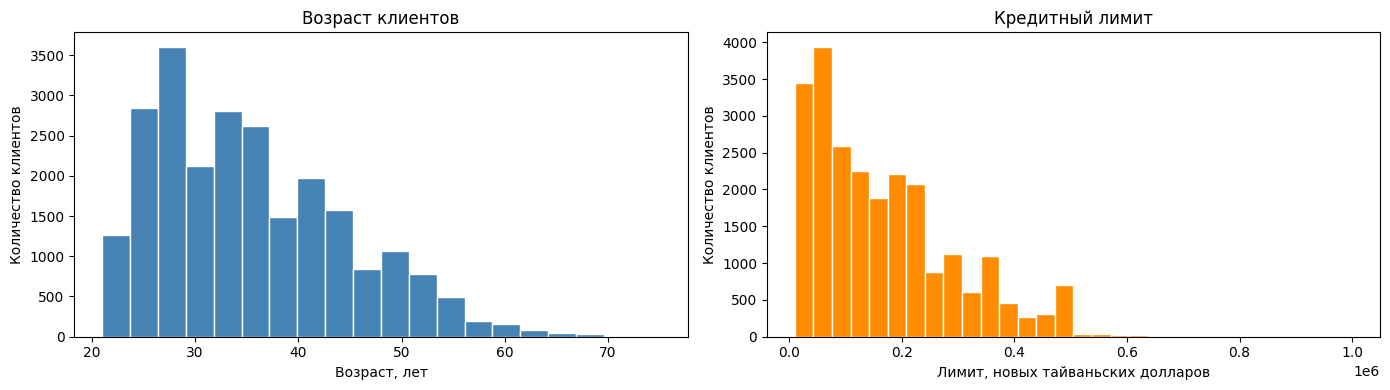

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Распределение возраста
axes[0].hist(
    train_clean["AGE"],
    bins=20,
    color="steelblue",
    edgecolor="white"
)
axes[0].set_title("Возраст клиентов")
axes[0].set_xlabel("Возраст, лет")
axes[0].set_ylabel("Количество клиентов")

# Распределение кредитного лимита
axes[1].hist(
    train_clean["LIMIT_BAL"],
    bins=30,
    color="darkorange",
    edgecolor="white"
)
axes[1].set_title("Кредитный лимит")
axes[1].set_xlabel("Лимит, новых тайваньских долларов")
axes[1].set_ylabel("Количество клиентов")

plt.tight_layout()
plt.show()

In [ ]:
pay_status_columns = [
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

# Для каждого месяца считаем количество каждого кода
status_counts = pd.DataFrame({
    column: train_clean[column].value_counts()
    for column in pay_status_columns
})

# Если код в каком-то месяце не встретился, ставим количество 0
status_counts = (
    status_counts
    .fillna(0)
    .astype(int)
    .sort_index()
)

display(status_counts)

,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
-2,2198,3030,3270,3477,3659,3942
-1,4527,4845,4733,4531,4417,4576
0,11781,12573,12636,13180,13560,13008
1,3000,25,3,2,0,0
2,2138,3145,3049,2542,2102,2230
3,245,254,192,143,142,149
4,58,78,60,53,65,42
5,18,21,16,28,13,8
6,10,11,19,3,3,11
7,9,17,20,40,38,33


In [ ]:
bill_columns = [f"BILL_AMT{i}" for i in range(1, 7)]
payment_columns = [f"PAY_AMT{i}" for i in range(1, 7)]

money_columns = bill_columns + payment_columns

money_summary = (
    train_clean[money_columns]
    .agg(["min", "max"])
    .T
)

money_summary["negative_count"] = (
    train_clean[money_columns] < 0
).sum()

display(money_summary)

,min,max,negative_count
BILL_AMT1,-165580.0,964511.0,468
BILL_AMT2,-69777.0,983931.0,522
BILL_AMT3,-61506.0,855086.0,515
BILL_AMT4,-81334.0,891586.0,530
BILL_AMT5,-81334.0,927171.0,524
BILL_AMT6,-339603.0,961664.0,556
PAY_AMT1,0.0,873552.0,0
PAY_AMT2,0.0,1215471.0,0
PAY_AMT3,0.0,896040.0,0
PAY_AMT4,0.0,621000.0,0


In [ ]:
def build_features(data):
    result = data.copy()

    status_columns = [
        "PAY_0", "PAY_2", "PAY_3",
        "PAY_4", "PAY_5", "PAY_6"
    ]
    bill_columns = [f"BILL_AMT{i}" for i in range(1, 7)]
    payment_columns = [f"PAY_AMT{i}" for i in range(1, 7)]

    # Считаем месяцы с положительным статусом задержки
    result["late_months_count"] = (
        result[status_columns] > 0
    ).sum(axis=1)

    # Для этого агрегата отрицательные коды заменяем на 0
    result["max_delay"] = (
        result[status_columns].clip(lower=0).max(axis=1)
    )

    result["bill_mean"] = result[bill_columns].mean(axis=1)
    result["payment_mean"] = result[payment_columns].mean(axis=1)

    # В нашем датасете кредитный лимит строго положительный
    result["latest_bill_to_limit"] = (
        result["BILL_AMT1"].clip(lower=0)
        / result["LIMIT_BAL"]
    )

    # Заранее заданные возрастные интервалы
    result["AGE_GROUP"] = pd.cut(
        result["AGE"],
        bins=[18, 30, 45, 60, float("inf")],
        labels=["18–29", "30–44", "45–59", "60+"],
        right=False
    )

    return result


train_features = build_features(train_clean)
test_features = build_features(test_clean)

new_columns = [
    "late_months_count",
    "max_delay",
    "bill_mean",
    "payment_mean",
    "latest_bill_to_limit",
    "AGE_GROUP"
]

display(train_features[["AGE"] + new_columns].head())

print("Размер обучающей таблицы:", train_features.shape)
print("Размер тестовой таблицы:", test_features.shape)

,AGE,late_months_count,max_delay,bill_mean,payment_mean,latest_bill_to_limit,AGE_GROUP
22788,33,4,3,165490.000000,6583.333333,1.011069,30–44
29006,34,1,1,8.833333,8.833333,0.000000,30–44
16950,50,2,2,8576.833333,669.333333,1.017100,45–59
22280,29,0,0,186262.333333,6947.833333,0.940359,18–29
11346,32,1,1,30.333333,254.333333,0.000000,30–44


Размер обучающей таблицы: (24000, 31)
Размер тестовой таблицы: (6000, 31)


## 2. Валидация данных и первые проверки


In [ ]:
%pip install -q "great-expectations==1.24.1"

In [ ]:
import great_expectations as gx

print("Версия Great Expectations:", gx.__version__)

# Создаём рабочую конфигурацию GX в памяти
gx_context = gx.get_context(mode="ephemeral")

# Указываем, что будем проверять таблицы pandas
data_source = gx_context.data_sources.add_pandas(
    name="credit_data"
)
data_asset = data_source.add_dataframe_asset(
    name="credit_clients"
)
batch_definition = data_asset.add_batch_definition_whole_dataframe(
    name="whole_table"
)

# Создаём набор правил — Expectation Suite
suite = gx.ExpectationSuite(name="credit_initial_checks")

# Разрешённые типы данных для трёх столбцов
column_types = {
    "AGE": ["int64"],
    "LIMIT_BAL": ["int64", "float64"],
    "default.payment.next.month": ["int64"]
}

# Для каждого столбца проверяем пропуски и тип
for column, allowed_types in column_types.items():
    suite.add_expectation(
        gx.expectations.ExpectColumnValuesToNotBeNull(
            column=column
        )
    )
    suite.add_expectation(
        gx.expectations.ExpectColumnValuesToBeInTypeList(
            column=column,
            type_list=allowed_types
        )
    )

# Возраст: от 18 до 100 включительно
suite.add_expectation(
    gx.expectations.ExpectColumnValuesToBeBetween(
        column="AGE",
        min_value=18,
        max_value=100
    )
)

# Лимит: строго больше нуля
suite.add_expectation(
    gx.expectations.ExpectColumnValuesToBeBetween(
        column="LIMIT_BAL",
        min_value=0,
        strict_min=True
    )
)

# Правильный ответ: только 0 или 1
suite.add_expectation(
    gx.expectations.ExpectColumnValuesToBeInSet(
        column="default.payment.next.month",
        value_set=[0, 1]
    )
)

suite = gx_context.suites.add(suite)

# Связываем источник данных с набором правил
validation_definition = gx_context.validation_definitions.add(
    gx.ValidationDefinition(
        name="validate_credit_data",
        data=batch_definition,
        suite=suite
    )
)

print("Набор из девяти проверок готов.")

INFO:great_expectations.data_context.types.base:Created temporary directory '/tmp/tmp_8sl46oo' for ephemeral docs site


Версия Great Expectations: 1.24.1
Набор из девяти проверок готов.


In [ ]:
validation_result = validation_definition.run(
    batch_parameters={"dataframe": train_df}
)

print("Все проверки пройдены:", validation_result.success)
print("Статистика:", validation_result.statistics)

# Останавливаем выполнение, если данные не прошли проверку
if not validation_result.success:
    raise ValueError("Данные не прошли обязательную валидацию.")

Calculating Metrics:   0%|          | 0/33 [00:00<?, ?it/s]

Все проверки пройдены: True
Статистика: {'evaluated_expectations': 9, 'successful_expectations': 9, 'unsuccessful_expectations': 0, 'success_percent': 100.0}


In [ ]:
# Создаём отдельную копию данных
bad_data = train_df.copy()

# Намеренно указываем невозможный возраст
first_index = bad_data.index[0]
bad_data.loc[first_index, "AGE"] = 250

bad_result = validation_definition.run(
    batch_parameters={"dataframe": bad_data}
)

print("Проверки пройдены:", bad_result.success)

# Показываем нарушенные правила
for check in bad_result.results:
    if not check.success:
        print("Столбец:", check.expectation_config.kwargs.get("column"))
        print("Нарушенное правило:", check.expectation_config.type)

# Проверяем, что наша защита действительно обнаружила ошибку
assert not bad_result.success, "Ошибка: некорректные данные прошли проверку!"

Calculating Metrics:   0%|          | 0/33 [00:00<?, ?it/s]

Проверки пройдены: False
Столбец: AGE
Нарушенное правило: expect_column_values_to_be_between


In [ ]:
# Описываем типы остальных столбцов
extra_types = {
    "ID": ["int64"],
    "SEX": ["int64"],
    "EDUCATION": ["int64"],
    "MARRIAGE": ["int64"]
}

status_columns = [
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]
bill_columns = [f"BILL_AMT{i}" for i in range(1, 7)]
payment_columns = [f"PAY_AMT{i}" for i in range(1, 7)]

for column in status_columns:
    extra_types[column] = ["int64"]

for column in bill_columns + payment_columns:
    extra_types[column] = ["int64", "float64"]

# Проверяем пропуски и типы остальных столбцов
for column, allowed_types in extra_types.items():
    suite.add_expectation(
        gx.expectations.ExpectColumnValuesToNotBeNull(
            column=column
        )
    )
    suite.add_expectation(
        gx.expectations.ExpectColumnValuesToBeInTypeList(
            column=column,
            type_list=allowed_types
        )
    )

# Проверяем наличие ровно тех столбцов, которые ожидаем
expected_columns = list(column_types) + list(extra_types)

suite.add_expectation(
    gx.expectations.ExpectTableColumnsToMatchSet(
        column_set=expected_columns,
        exact_match=True
    )
)

# Таблица не должна быть пустой
suite.add_expectation(
    gx.expectations.ExpectTableRowCountToBeBetween(
        min_value=1
    )
)

# Правила для идентификаторов
suite.add_expectation(
    gx.expectations.ExpectColumnValuesToBeUnique(column="ID")
)
suite.add_expectation(
    gx.expectations.ExpectColumnValuesToBeBetween(
        column="ID", min_value=0, strict_min=True
    )
)

# Допустимые коды в исходных данных, ДО очистки
allowed_categories = {
    "SEX": [1, 2],
    "EDUCATION": [0, 1, 2, 3, 4, 5, 6],
    "MARRIAGE": [0, 1, 2, 3]
}

for column in status_columns:
    allowed_categories[column] = list(range(-2, 10))

for column, allowed_values in allowed_categories.items():
    suite.add_expectation(
        gx.expectations.ExpectColumnValuesToBeInSet(
            column=column,
            value_set=allowed_values
        )
    )

# Внесённые платежи должны быть неотрицательными
for column in payment_columns:
    suite.add_expectation(
        gx.expectations.ExpectColumnValuesToBeBetween(
            column=column,
            min_value=0
        )
    )

print("Ожидаемое количество столбцов:", len(expected_columns))
print("Количество правил:", len(suite.expectations))

Ожидаемое количество столбцов: 25
Количество правил: 72


In [ ]:
def validate_credit_data(data):
    result = validation_definition.run(
        batch_parameters={"dataframe": data}
    )

    if not result.success:
        failed_checks = []

        for check in result.results:
            if not check.success:
                column = check.expectation_config.kwargs.get(
                    "column", "вся таблица"
                )
                rule = check.expectation_config.type
                failed_checks.append(f"{column}: {rule}")

        raise ValueError(
            "Данные не прошли валидацию:\n"
            + "\n".join(failed_checks)
        )

    return result


# Проверяем обе исходные выборки одинаковыми правилами
for name, data in [
    ("Обучение", train_df),
    ("Тест", test_df)
]:
    result = validate_credit_data(data)
    print(
        f"{name}: проверки пройдены — {result.success}; "
        f"правил — {result.statistics['evaluated_expectations']}"
    )

Calculating Metrics:   0%|          | 0/228 [00:00<?, ?it/s]

Обучение: проверки пройдены — True; правил — 72


Calculating Metrics:   0%|          | 0/228 [00:00<?, ?it/s]

Тест: проверки пройдены — True; правил — 72


In [ ]:
%pip install -q pytest

In [ ]:
import pytest


def test_valid_data():
    sample = train_df.head(100).copy()

    result = validate_credit_data(sample)

    assert result.success


def test_negative_payment_is_rejected():
    sample = train_df.head(100).copy()
    first_index = sample.index[0]

    # Намеренно создаём отрицательный внесённый платёж
    sample.loc[first_index, "PAY_AMT1"] = -100.0

    with pytest.raises(ValueError, match="PAY_AMT1"):
        validate_credit_data(sample)


def test_unknown_status_is_rejected():
    sample = train_df.head(100).copy()
    first_index = sample.index[0]

    # Такого статуса в нашем наборе допустимых кодов нет
    sample.loc[first_index, "PAY_0"] = 99

    with pytest.raises(ValueError, match="PAY_0"):
        validate_credit_data(sample)


def test_negative_bill_is_allowed():
    sample = train_df.head(100).copy()
    first_index = sample.index[0]

    # Отрицательная сумма счёта разрешена
    sample.loc[first_index, "BILL_AMT1"] = -100.0

    result = validate_credit_data(sample)

    assert result.success

In [ ]:
# Создаём копию первых 100 строк
sample = train_df.head(100).copy()

# Намеренно добавляем отрицательный платёж
first_index = sample.index[0]
sample.loc[first_index, "PAY_AMT1"] = -100.0

# Ожидаем, что валидация отклонит эти данные
with pytest.raises(ValueError, match="PAY_AMT1"):
    validate_credit_data(sample)

print("Тест пройден: отрицательный платёж обнаружен.")

Calculating Metrics:   0%|          | 0/228 [00:00<?, ?it/s]

Тест пройден: отрицательный платёж обнаружен.


In [ ]:
tests = [
    test_valid_data,
    test_negative_payment_is_rejected,
    test_unknown_status_is_rejected,
    test_negative_bill_is_allowed
]

for test in tests:
    test()
    print(f"Пройден: {test.__name__}")

print("\nВсе четыре теста пройдены.")

Calculating Metrics:   0%|          | 0/228 [00:00<?, ?it/s]

Пройден: test_valid_data


Calculating Metrics:   0%|          | 0/228 [00:00<?, ?it/s]

Пройден: test_negative_payment_is_rejected


Calculating Metrics:   0%|          | 0/228 [00:00<?, ?it/s]

Пройден: test_unknown_status_is_rejected


Calculating Metrics:   0%|          | 0/228 [00:00<?, ?it/s]

Пройден: test_negative_bill_is_allowed

Все четыре теста пройдены.


## 3. Создание sklearn Pipeline


In [ ]:
target = "default.payment.next.month"

# На вход Pipeline подаём исходные признаки
X_train = train_df.drop(columns=["ID", target])
y_train = train_df[target].copy()

X_test = test_df.drop(columns=["ID", target])
y_test = test_df[target].copy()

print("Обучающие признаки:", X_train.shape)
print("Обучающие ответы:", y_train.shape)

print("Тестовые признаки:", X_test.shape)
print("Тестовые ответы:", y_test.shape)

Обучающие признаки: (24000, 23)
Обучающие ответы: (24000,)
Тестовые признаки: (6000, 23)
Тестовые ответы: (6000,)


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression


# Объединяем нашу очистку и создание признаков
def prepare_features(data):
    cleaned = clean_categories(data)
    return build_features(cleaned)


status_columns = [
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]
bill_columns = [f"BILL_AMT{i}" for i in range(1, 7)]
payment_columns = [f"PAY_AMT{i}" for i in range(1, 7)]

# Числовые признаки после создания новых столбцов
numeric_features = (
    ["LIMIT_BAL", "AGE"]
    + bill_columns
    + payment_columns
    + [
        "late_months_count",
        "max_delay",
        "bill_mean",
        "payment_mean",
        "latest_bill_to_limit"
    ]
)

# Эти числовые коды рассматриваем как названия категорий
categorical_features = (
    ["SEX", "EDUCATION", "MARRIAGE"]
    + status_columns
    + ["AGE_GROUP"]
)

# Обработка числовых признаков
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Обработка категориальных признаков
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Направляем каждую группу столбцов в свою обработку
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Полная последовательность обработки и модель
model_pipeline = Pipeline(steps=[
    (
        "features",
        FunctionTransformer(prepare_features, validate=False)
    ),
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

print("Числовых признаков:", len(numeric_features))
print("Категориальных признаков:", len(categorical_features))

display(model_pipeline)

Числовых признаков: 19
Категориальных признаков: 10


Pipeline(steps=[('features',
                 FunctionTransformer(func=<function prepare_features at 0x7c027e8e2520>)),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['LIMIT_BAL', 'AGE',
                                                   'BILL_AMT1', 'BILL_AMT2',
                                                   'BILL_AMT3', 'BILL_AMT4',
                                                   'BILL_AMT5', 'BILL_AMT6',
                                                   'PAY_AMT1', 'PAY...
                                                   'late_months_count',
                                                   'max_delay', 'bill_mean',
                                                   'payment_mean',
                                                   'latest_bill_to_limit']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['SEX', 'EDUCATION',
                                                   'MARRIAGE', 'PAY_0', 'PAY_2',
                                                   'PAY_3', 'PAY_4', 'PAY_5',
                                                   'PAY_6', 'AGE_GROUP'])])),
                ('classifier', LogisticRegression(max_iter=2000))])

## 4. Эксперименты MLflow, кросс-валидация и выбор параметров


In [ ]:
%pip install -q "mlflow==3.17.2"

In [ ]:
import mlflow
import mlflow.sklearn
from pathlib import Path

# Все результаты MLflow складываем в одну папку
tracking_folder = Path("/content/pd_mlflow")
tracking_folder.mkdir(parents=True, exist_ok=True)

database_path = tracking_folder / "mlflow.db"

# В SQLite будут храниться параметры и метрики
mlflow.set_tracking_uri(f"sqlite:///{database_path}")

experiment_name = "PD_Credit_Scoring"

experiment = mlflow.get_experiment_by_name(experiment_name)

if experiment is None:
    experiment_id = mlflow.create_experiment(
        name=experiment_name,
        artifact_location=(
            tracking_folder / "artifacts"
        ).as_uri()
    )
else:
    experiment_id = experiment.experiment_id

mlflow.set_experiment(experiment_name)

print("Версия MLflow:", mlflow.__version__)
print("Эксперимент:", experiment_name)
print("ID эксперимента:", experiment_id)

2026/11/04 21:35:01 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/04 21:35:01 INFO mlflow.store.db.utils: Updating database tables


Версия MLflow: 3.17.2
Эксперимент: PD_Credit_Scoring
ID эксперимента: 1


Calculating Metrics:   0%|          | 0/228 [00:00<?, ?it/s]

Началась кросс-валидация на пяти частях...


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:   10.1s finished


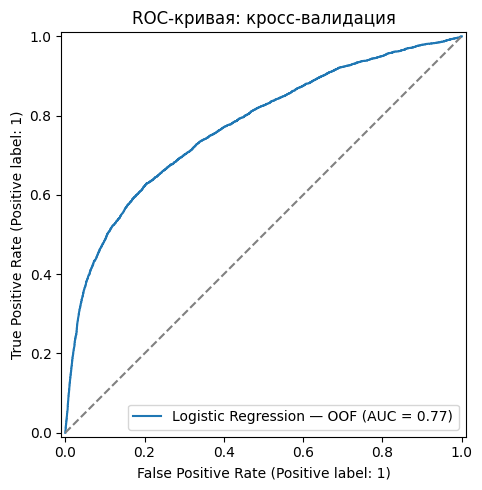

Обучаем Pipeline на всех 24 000 клиентах...


2026/11/04 21:35:21 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
  warnings.warn(

  warnings.warn(




Эксперимент завершён.
Run ID: 9995585e600d4ef4a0aa8cfcd390a4fd
cv_oof_roc_auc: 0.7724
cv_oof_precision: 0.6816
cv_oof_recall: 0.3617
cv_oof_f1: 0.4726


In [ ]:
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict
)
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    RocCurveDisplay
)

# Проверка данных перед обучением
validate_credit_data(train_df)

# Фиксируем разбиение для воспроизводимости
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

threshold = 0.5

with mlflow.start_run(
    run_name="01_logistic_regression_baseline"
) as run:

    # Записываем настройки модели
    mlflow.log_params(
        model_pipeline.named_steps["classifier"].get_params()
    )

    mlflow.log_params({
        "cv_folds": 5,
        "cv_random_state": 42,
        "threshold": threshold,
        "engineered_features": True,
        "training_rows": len(X_train)
    })

    print("Началась кросс-валидация на пяти частях...")

    # Для каждого клиента получаем вероятность дефолта
    # от модели, которая не обучалась на этом клиенте
    oof_probabilities = cross_val_predict(
        model_pipeline,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1,
        verbose=1
    )[:, 1]

    # Превращаем вероятности в классы по порогу 0.5
    oof_predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    # Общие метрики по вневыборочным прогнозам
    metrics = {
        "cv_oof_roc_auc": roc_auc_score(
            y_train, oof_probabilities
        ),
        "cv_oof_precision": precision_score(
            y_train, oof_predictions, zero_division=0
        ),
        "cv_oof_recall": recall_score(
            y_train, oof_predictions, zero_division=0
        ),
        "cv_oof_f1": f1_score(
            y_train, oof_predictions, zero_division=0
        )
    }

    mlflow.log_metrics(metrics)

    # Строим и сохраняем ROC-кривую
    fig, ax = plt.subplots(figsize=(6, 5))

    RocCurveDisplay.from_predictions(
        y_train,
        oof_probabilities,
        name="Logistic Regression — OOF",
        ax=ax
    )

    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set_title("ROC-кривая: кросс-валидация")
    fig.tight_layout()

    mlflow.log_figure(fig, "roc_curve_cv.png")
    plt.show()
    plt.close(fig)

    # Сохраняем метрики также отдельным артефактом
    mlflow.log_dict(metrics, "cv_metrics.json")

    print("Обучаем Pipeline на всех 24 000 клиентах...")

    model_pipeline.fit(X_train, y_train)

    # Сохраняем весь обученный Pipeline
    model_info = mlflow.sklearn.log_model(
        sk_model=model_pipeline,
        name="pd_model",
        input_example=X_train.head(5),
        serialization_format="cloudpickle"
    )

    baseline_run_id = run.info.run_id

print("\nЭксперимент завершён.")
print("Run ID:", baseline_run_id)

for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

In [ ]:
import shutil
import sqlite3
from google.colab import files

backup_folder = Path("/content/pd_mlflow_backup")
backup_folder.mkdir(parents=True, exist_ok=True)

# Создаём согласованную копию базы журнала
with sqlite3.connect(str(database_path)) as source:
    with sqlite3.connect(
        str(backup_folder / "mlflow.db")
    ) as destination:
        source.backup(destination)

# Копируем модели, графики и остальные артефакты
shutil.copytree(
    tracking_folder / "artifacts",
    backup_folder / "artifacts",
    dirs_exist_ok=True
)

archive_path = shutil.make_archive(
    "/content/pd_mlflow_checkpoint",
    "zip",
    root_dir=backup_folder
)

files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
threshold_rows = []

for current_threshold in [0.5, 0.4, 0.3, 0.2]:
    predictions = (
        oof_probabilities >= current_threshold
    ).astype(int)

    threshold_rows.append({
        "threshold": current_threshold,
        "precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_train, predictions, zero_division=0
        ),
        "flagged_clients": int(predictions.sum())
    })

threshold_comparison = pd.DataFrame(threshold_rows)

display(threshold_comparison.round(4))

# Дописываем таблицу в существующий запуск MLflow
with mlflow.start_run(run_id=baseline_run_id):
    mlflow.log_dict(
        {"results": threshold_rows},
        "threshold_comparison.json"
    )

,threshold,precision,recall,f1,flagged_clients
0,0.5,0.6816,0.3617,0.4726,2817
1,0.4,0.6315,0.4251,0.5082,3574
2,0.3,0.5464,0.5259,0.5359,5110
3,0.2,0.4440,0.6453,0.5260,7717


In [ ]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Общий порог для сравнения вариантов
comparison_threshold = 0.3


# Метрики для одной проверочной части
def score_model(estimator, features, answers):
    probabilities = estimator.predict_proba(features)[:, 1]

    predictions = (
        probabilities >= comparison_threshold
    ).astype(int)

    return {
        "roc_auc": roc_auc_score(answers, probabilities),
        "precision": precision_score(
            answers, predictions, zero_division=0
        ),
        "recall": recall_score(
            answers, predictions, zero_division=0
        ),
        "f1": f1_score(
            answers, predictions, zero_division=0
        )
    }


# Одинаковые разбиения для всех пяти вариантов
search_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=clone(model_pipeline),
    param_grid={
        "classifier__C": [0.001, 0.01, 0.1, 1.0, 10.0]
    },
    scoring=score_model,
    refit="roc_auc",
    cv=search_cv,
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

# Проверка входных данных перед обучением
validate_credit_data(train_df)

search.fit(X_train, y_train)

# Показываем средние результаты по пяти частям
search_summary = pd.DataFrame(search.cv_results_)[[
    "param_classifier__C",
    "mean_test_roc_auc",
    "std_test_roc_auc",
    "mean_test_precision",
    "mean_test_recall",
    "mean_test_f1",
    "rank_test_roc_auc"
]].sort_values("rank_test_roc_auc")

display(search_summary.round(4))

best_pipeline = search.best_estimator_

print("Лучшие параметры:", search.best_params_)
print("Лучший средний ROC-AUC:", round(search.best_score_, 4))

Calculating Metrics:   0%|          | 0/228 [00:00<?, ?it/s]

Fitting 5 folds for each of 5 candidates, totalling 25 fits


,param_classifier__C,mean_test_roc_auc,std_test_roc_auc,mean_test_precision,mean_test_recall,mean_test_f1,rank_test_roc_auc
2,0.100,0.7726,0.0058,0.5509,0.5251,0.5377,1
3,1.000,0.7725,0.0059,0.5464,0.5259,0.5360,2
4,10.000,0.7723,0.0062,0.5460,0.5259,0.5358,3
1,0.010,0.7722,0.0053,0.5553,0.5178,0.5359,4
0,0.001,0.7687,0.0056,0.5441,0.5178,0.5306,5


Лучшие параметры: {'classifier__C': 0.1}
Лучший средний ROC-AUC: 0.7726


In [ ]:
search_run_ids = []

for index, params in enumerate(search.cv_results_["params"]):
    current_c = float(params["classifier__C"])

    with mlflow.start_run(
        run_name=f"LR_grid_C_{current_c:g}"
    ) as run:

        # Выбранный вариант уже обучен GridSearchCV
        if index == search.best_index_:
            candidate = search.best_estimator_
        else:
            candidate = clone(model_pipeline).set_params(**params)
            candidate.fit(X_train, y_train)

        mlflow.log_params(
            candidate.named_steps["classifier"].get_params()
        )

        mlflow.log_params({
            "cv_folds": 5,
            "cv_random_state": 42,
            "threshold": comparison_threshold,
            "engineered_features": True
        })

        candidate_metrics = {}

        for metric_name in ["roc_auc", "precision", "recall", "f1"]:
            candidate_metrics[f"cv_{metric_name}_mean"] = float(
                search.cv_results_[f"mean_test_{metric_name}"][index]
            )
            candidate_metrics[f"cv_{metric_name}_std"] = float(
                search.cv_results_[f"std_test_{metric_name}"][index]
            )

        mlflow.log_metrics(candidate_metrics)

        mlflow.log_dict(
            {"decision_threshold": comparison_threshold},
            "decision_policy.json"
        )

        mlflow.sklearn.log_model(
            sk_model=candidate,
            name="pd_model",
            input_example=X_train.head(5),
            serialization_format="cloudpickle"
        )

        search_run_ids.append(run.info.run_id)

    print(f"Сохранён вариант C={current_c:g}")

print("\nПять вариантов сохранены в MLflow.")

2026/11/04 21:36:04 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
  warnings.warn(

  warnings.warn(



Сохранён вариант C=0.001


2026/11/04 21:36:11 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
  warnings.warn(

  warnings.warn(

2026/11/04 21:36:15 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
  warnings.warn(

  warnings.warn(



Сохранён вариант C=0.01
Сохранён вариант C=0.1


2026/11/04 21:36:20 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
  warnings.warn(

  warnings.warn(



Сохранён вариант C=1


2026/11/04 21:36:27 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
  warnings.warn(

  warnings.warn(



Сохранён вариант C=10

Пять вариантов сохранены в MLflow.


In [ ]:
import sys
import subprocess
import time
import psutil

from pathlib import Path
from urllib.request import urlopen
from urllib.error import URLError
from google.colab import output

# Останавливаем ранее запущенный нами интерфейс
if (
    "mlflow_ui_process" in globals()
    and mlflow_ui_process.poll() is None
):
    try:
        parent = psutil.Process(mlflow_ui_process.pid)
        processes = parent.children(recursive=True) + [parent]

        for process in processes:
            try:
                process.terminate()
            except psutil.NoSuchProcess:
                pass

        _, alive = psutil.wait_procs(processes, timeout=10)

        for process in alive:
            try:
                process.kill()
            except psutil.NoSuchProcess:
                pass

        psutil.wait_procs(alive, timeout=5)

    except psutil.NoSuchProcess:
        pass

log_path = Path("/content/mlflow_ui.log")

command = [
    sys.executable, "-m", "mlflow", "server",
    "--backend-store-uri", mlflow.get_tracking_uri(),
    "--host", "127.0.0.1",
    "--port", "5000",
    "--workers", "1",
    "--allowed-hosts", (
        "127.0.0.1,127.0.0.1:*,localhost,localhost:*,"
        "*.googleusercontent.com,*.googleusercontent.com:*,"
        "*.datalab-user-runtimes.internal,"
        "*.datalab-user-runtimes.internal:*"
    ),
    "--cors-allowed-origins", (
        "https://colab.research.google.com,"
        "https://*.googleusercontent.com"
    ),
    "--x-frame-options", "NONE"
]

with log_path.open("w") as log_file:
    mlflow_ui_process = subprocess.Popen(
        command,
        stdout=log_file,
        stderr=subprocess.STDOUT
    )

# Ждём готовности сервера
for attempt in range(30):
    if mlflow_ui_process.poll() is not None:
        raise RuntimeError(log_path.read_text()[-5000:])

    try:
        with urlopen(
            "http://127.0.0.1:5000/",
            timeout=1
        ) as response:
            if response.status == 200:
                break
    except (URLError, TimeoutError):
        time.sleep(1)
else:
    raise RuntimeError(log_path.read_text()[-5000:])

output.serve_kernel_port_as_iframe(5000, height=800)

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path

log_text = Path("/content/mlflow_ui.log").read_text()

host_messages = [
    line
    for line in log_text.splitlines()
    if "invalid host" in line.lower()
]

print(
    "\n".join(host_messages[-5:])
    if host_messages
    else log_text[-3000:]
)

Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled. Allowed hosts: 127.0.0.1, 127.0.0.1:*, localhost, and 5 more. CORS origins: https://colab.research.google.com, https://*.googleusercontent.com.
2026/11/04 21:36:39 INFO mlflow.server.jobs.executor_registry: Available backends after discovery: local
2026/11/04 21:36:39 INFO mlflow.server.jobs.executor_registry: Job executor backend 'local' passed requirements check
/usr/local/lib/python3.13/dist-packages/mlflow/server/fastapi_app.py:23: StarletteDeprecationWarning: starlette.middleware.wsgi is deprecated and will be removed in a future release. Please refer to https://github.com/abersheeran/a2wsgi as a replacement.
  from starlette.middleware.wsgi import WSGIResponder, build_environ
2026/11/04 21:36:49 INFO:     Started server process [2816]
2026/11/04 21:36:49 INFO:     Waiting for application startup.
2026/11/04 21:36:50 INFO:     Application startup complete.
2026/11/04 21:36:50 INFO:     

In [ ]:
import re
import sys
import time
import subprocess
from pathlib import Path
from urllib.parse import urlsplit
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError
from google.colab import output

# Получаем точный адрес отклонённого запроса
old_log = Path("/content/mlflow_ui.log").read_text()

matches = re.findall(
    r"Rejected request with invalid Host header:\s*(\S+)",
    old_log
)

if not matches:
    raise RuntimeError(
        "Адрес не найден в журнале:\n" + old_log[-3000:]
    )

blocked_host = matches[-1]
print("Добавляем разрешённый адрес:", blocked_host)

# Новый порт для отдельного запуска интерфейса
ui_port = 5051

proxy_url = output.eval_js(
    f"google.colab.kernel.proxyPort({ui_port})"
)
proxy_address = urlsplit(proxy_url)

allowed_hosts = {
    "127.0.0.1",
    f"127.0.0.1:{ui_port}",
    "localhost",
    f"localhost:{ui_port}",
    blocked_host,
    proxy_address.hostname,
    proxy_address.netloc
}

allowed_origins = {
    "https://colab.research.google.com",
    f"{proxy_address.scheme}://{proxy_address.netloc}"
}

new_log_path = Path("/content/mlflow_ui_5051.log")

if (
    "mlflow_ui_5051_process" not in globals()
    or mlflow_ui_5051_process.poll() is not None
):
    new_command = [
        sys.executable, "-m", "mlflow", "server",
        "--backend-store-uri", mlflow.get_tracking_uri(),
        "--host", "127.0.0.1",
        "--port", str(ui_port),
        "--workers", "1",
        "--allowed-hosts",
        ",".join(sorted(host for host in allowed_hosts if host)),
        "--cors-allowed-origins",
        ",".join(sorted(allowed_origins)),
        "--x-frame-options", "NONE"
    ]

    with new_log_path.open("w") as log_file:
        mlflow_ui_5051_process = subprocess.Popen(
            new_command,
            stdout=log_file,
            stderr=subprocess.STDOUT,
            start_new_session=True
        )

# Проверяем запрос именно с ранее отклонённым Host
request = Request(
    f"http://127.0.0.1:{ui_port}/",
    headers={"Host": blocked_host}
)

for attempt in range(30):
    if mlflow_ui_5051_process.poll() is not None:
        raise RuntimeError(new_log_path.read_text()[-5000:])

    try:
        with urlopen(request, timeout=1) as response:
            print("Проверка адреса — HTTP:", response.status)
            break
    except HTTPError as error:
        raise RuntimeError(
            f"Сервер ответил HTTP {error.code}:\n"
            + error.read().decode(errors="replace")[:1000]
            + "\nЖурнал:\n"
            + new_log_path.read_text()[-3000:]
        ) from error
    except (URLError, TimeoutError):
        time.sleep(1)
else:
    raise RuntimeError(new_log_path.read_text()[-5000:])

output.serve_kernel_port_as_iframe(
    ui_port,
    path=f"/?refresh={int(time.time())}",
    height=800,
    cache_in_notebook=False
)

RuntimeError: Адрес не найден в журнале:
Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled. Allowed hosts: 127.0.0.1, 127.0.0.1:*, localhost, and 5 more. CORS origins: https://colab.research.google.com, https://*.googleusercontent.com.
2026/11/04 21:36:39 INFO mlflow.server.jobs.executor_registry: Available backends after discovery: local
2026/11/04 21:36:39 INFO mlflow.server.jobs.executor_registry: Job executor backend 'local' passed requirements check
/usr/local/lib/python3.13/dist-packages/mlflow/server/fastapi_app.py:23: StarletteDeprecationWarning: starlette.middleware.wsgi is deprecated and will be removed in a future release. Please refer to https://github.com/abersheeran/a2wsgi as a replacement.
  from starlette.middleware.wsgi import WSGIResponder, build_environ
2026/11/04 21:36:49 INFO:     Started server process [2816]
2026/11/04 21:36:49 INFO:     Waiting for application startup.
2026/11/04 21:36:50 INFO:     Application startup

## 5. Итоговая оценка на отложенном тесте


In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Фиксируем выбранную модель и порог ДО проверки теста
final_model = best_pipeline
final_threshold = 0.3

selected_run_id = search_run_ids[search.best_index_]

print(
    "Выбранное C:",
    final_model.named_steps["classifier"].C
)
print("Зафиксированный порог:", final_threshold)

# Проверяем исходные тестовые данные
validate_credit_data(test_df)

# Прогнозируем вероятности для отложенных клиентов
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Применяем наш выбранный порог
test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

test_metrics = {
    "test_roc_auc": roc_auc_score(
        y_test, test_probabilities
    ),
    "test_precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "test_recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "test_f1": f1_score(
        y_test, test_predictions, zero_division=0
    )
}

print("\nМетрики на отложенной тестовой выборке:")

for name, value in test_metrics.items():
    print(f"{name}: {value:.4f}")

# Матрица ошибок: строки — факт, столбцы — прогноз
cm = confusion_matrix(
    y_test, test_predictions, labels=[0, 1]
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities,
    name="Logistic Regression",
    ax=axes[0]
)
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("ROC-кривая: отложенный тест")

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Без дефолта", "Дефолт"]
).plot(
    ax=axes[1],
    cmap="Blues",
    colorbar=False
)

axes[1].set_title("Матрица ошибок: порог 0,3")
axes[1].set_xlabel("Прогноз модели")
axes[1].set_ylabel("Фактический класс")

fig.tight_layout()

# Сохраняем итоговую оценку в запуск выбранной модели
with mlflow.start_run(run_id=selected_run_id):
    mlflow.log_metrics(test_metrics)
    mlflow.log_dict(test_metrics, "test_metrics.json")
    mlflow.log_figure(fig, "test_evaluation.png")
    mlflow.set_tag("selected_for_project", "true")

plt.show()
plt.close(fig)

print("\nИтоговая оценка сохранена в MLflow.")

In [ ]:
import shutil
import sqlite3

from pathlib import Path
from google.colab import files

source_folder = Path("/content/pd_mlflow")
backup_folder = Path("/content/pd_mlflow_backup")
backup_folder.mkdir(parents=True, exist_ok=True)

# Создаём согласованную копию базы MLflow
with sqlite3.connect(str(source_folder / "mlflow.db")) as source:
    with sqlite3.connect(str(backup_folder / "mlflow.db")) as destination:
        source.backup(destination)

# Копируем сохранённые модели, графики и отчёты
shutil.copytree(
    source_folder / "artifacts",
    backup_folder / "artifacts",
    dirs_exist_ok=True,
)

archive_path = shutil.make_archive(
    "/content/pd_mlflow_checkpoint",
    "zip",
    root_dir=backup_folder,
)

files.download(archive_path)

## 6. Восстановление после завершения сессии Colab

Этот раздел содержит диагностические попытки; успешное восстановление из файлов резервной копии показано ниже.


In [ ]:
from pathlib import Path

print("Переменные в памяти:")
for name in [
    "train_df",
    "test_df",
    "final_model",
    "selected_run_id",
]:
    status = "есть" if name in globals() else "нет"
    print(f"  {name}: {status}")

print("\nФайлы:")
for filename in [
    "/content/data/raw/UCI_Credit_Card.csv",
    "/content/pd_mlflow/mlflow.db",
    "/content/pd_mlflow/artifacts",
]:
    status = "есть" if Path(filename).exists() else "нет"
    print(f"  {filename}: {status}")

In [ ]:
from google.colab import files

uploaded = files.upload()

print("\nЗагруженные файлы:")
for filename in uploaded:
    print(filename)

In [ ]:
from pathlib import Path
from zipfile import ZipFile
import sqlite3

# 1. Восстанавливаем исходный датасет
raw_folder = Path("/content/data/raw")
raw_folder.mkdir(parents=True, exist_ok=True)

with ZipFile("/content/archive.zip") as archive:
    csv_files = [
        name for name in archive.namelist()
        if Path(name).name == "UCI_Credit_Card.csv"
    ]
    if len(csv_files) != 1:
        raise ValueError("В архиве не найден единственный UCI_Credit_Card.csv")

    raw_path = raw_folder / "UCI_Credit_Card.csv"
    raw_path.write_bytes(archive.read(csv_files[0]))

# 2. Восстанавливаем MLflow по прежнему адресу
tracking_folder = Path("/content/pd_mlflow")
tracking_folder.mkdir(parents=True, exist_ok=True)

with ZipFile("/content/pd_mlflow_checkpoint.zip") as archive:
    archive.extractall(tracking_folder)

# 3. Проверяем содержимое
database_path = tracking_folder / "mlflow.db"
if not database_path.exists():
    raise FileNotFoundError("В резервной копии не найдена база mlflow.db")

print("Датасет восстановлен:", raw_path.exists())

with sqlite3.connect(
    f"file:{database_path}?mode=ro", uri=True
) as connection:
    run_count = connection.execute(
        "SELECT COUNT(*) FROM runs"
    ).fetchone()[0]

print("Запусков в базе MLflow:", run_count)

model_files = sorted(tracking_folder.rglob("MLmodel"))
print("Сохранённых моделей:", len(model_files))

# Узнаём версии библиотек, с которыми сохранялась модель
requirements_files = sorted(tracking_folder.rglob("requirements.txt"))
if requirements_files:
    print("\nЗависимости сохранённой модели:")
    print(requirements_files[0].read_text())
else:
    print("\nФайл зависимостей модели не найден.")

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving pd_mlflow_checkpoint (1).zip to pd_mlflow_checkpoint (1).zip


In [ ]:
from pathlib import Path
from zipfile import ZipFile
import sqlite3
import tempfile

# Берём файл из последней загрузки
if len(uploaded) != 1:
    raise ValueError("Нужно загрузить только один новый архив.")

backup_archive = Path(next(iter(uploaded)))
print("Проверяем архив:", backup_archive.name)

# Распаковываем в отдельную папку
checked_folder = Path(
    tempfile.mkdtemp(prefix="pd_checkpoint_check_", dir="/content")
)

with ZipFile(backup_archive) as archive:
    archive.extractall(checked_folder)

database = checked_folder / "mlflow.db"
if not database.exists():
    raise FileNotFoundError("В архиве не найдена база mlflow.db")

with sqlite3.connect(
    f"file:{database}?mode=ro", uri=True
) as connection:
    count = connection.execute(
        "SELECT COUNT(*) FROM runs"
    ).fetchone()[0]
    print("\nЗапусков:", count)

    print("\nНазвания запусков:")
    for (name,) in connection.execute("""
        SELECT value FROM tags
        WHERE key = 'mlflow.runName'
        ORDER BY value
    """):
        print(" ", name)

    selected = connection.execute("""
        SELECT run_uuid FROM tags
        WHERE key = 'selected_for_project' AND value = 'true'
    """).fetchall()

    print("\nОтмеченных итоговых запусков:", len(selected))

    for (run_id,) in selected:
        print("\nМетрики итоговой модели:")
        for key, value in connection.execute("""
            SELECT key, value FROM latest_metrics
            WHERE run_uuid = ? AND key LIKE 'test_%'
            ORDER BY key
        """, (run_id,)):
            print(f"  {key}: {value:.4f}")

print("\nСохранённых моделей:", len(list(checked_folder.rglob("MLmodel"))))

Проверяем архив: pd_mlflow_checkpoint (1).zip

Запусков: 6

Названия запусков:
  01_logistic_regression_baseline
  LR_grid_C_0.001
  LR_grid_C_0.01
  LR_grid_C_0.1
  LR_grid_C_1
  LR_grid_C_10

Отмеченных итоговых запусков: 1

Метрики итоговой модели:
  test_f1: 0.5203
  test_precision: 0.5392
  test_recall: 0.5026
  test_roc_auc: 0.7613

Сохранённых моделей: 6


In [ ]:
from pathlib import Path
import shutil
import tempfile
import subprocess
import sys

tracking_folder = Path("/content/pd_mlflow")

# Убираем раннюю копию в отдельную резервную папку
if tracking_folder.exists():
    previous_folder = Path(
        tempfile.mkdtemp(prefix="pd_previous_", dir="/content")
    )
    shutil.move(
        str(tracking_folder),
        str(previous_folder / "pd_mlflow"),
    )

# Восстанавливаем проверенную полную копию
shutil.copytree(checked_folder, tracking_folder)

# Находим список версий библиотек сохранённой модели
requirements_files = sorted(
    tracking_folder.rglob("requirements.txt")
)
if not requirements_files:
    raise FileNotFoundError("Не найден список зависимостей модели")

# Устанавливаем эти версии
subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "-q", "-r", str(requirements_files[0]),
])

print("Полная копия восстановлена. Библиотеки установлены.")

Полная копия восстановлена. Библиотеки установлены.


In [ ]:
from pathlib import Path

import pandas as pd
import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient
from sklearn.model_selection import train_test_split

# Подключаем восстановленную базу
database_path = Path("/content/pd_mlflow/mlflow.db")
mlflow.set_tracking_uri(f"sqlite:///{database_path}")

client = MlflowClient()
experiment = client.get_experiment_by_name("PD_Credit_Scoring")
if experiment is None:
    raise ValueError("Эксперимент PD_Credit_Scoring не найден")

# Ищем именно вчерашний выбранный запуск
all_runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    max_results=1000,
)

selected_runs = [
    run for run in all_runs
    if run.data.tags.get("mlflow.runName") == "LR_grid_C_0.1"
]

print("Всего запусков в подключённой базе:", len(all_runs))
print("Найдено запусков LR_grid_C_0.1:", len(selected_runs))

if len(selected_runs) != 1:
    display(pd.DataFrame([
        {
            "Название": run.data.tags.get("mlflow.runName"),
            "Run ID": run.info.run_id,
            "C": run.data.params.get("C"),
        }
        for run in all_runs
    ]))

# Загружаем обученную модель и сохранённый порог
final_model = mlflow.sklearn.load_model(
    f"runs:/{selected_run_id}/pd_model"
)
final_threshold = float(selected_run.data.params["threshold"])

print("Модель:", selected_run.data.tags["mlflow.runName"])
print("C:", final_model.named_steps["classifier"].C)
print("Порог:", final_threshold)

# Восстанавливаем прежнее разделение данных
df = pd.read_csv("/content/data/raw/UCI_Credit_Card.csv")
target = "default.payment.next.month"

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df[target],
)

X_train = train_df.drop(columns=["ID", target])
y_train = train_df[target].copy()
X_test = test_df.drop(columns=["ID", target])
y_test = test_df[target].copy()

# Проверяем прогноз на пяти обучающих строках
probabilities = final_model.predict_proba(X_train.head(5))[:, 1]

display(pd.DataFrame({
    "ID": train_df["ID"].head(5).to_numpy(),
    "Вероятность дефолта": probabilities.round(4),
    "Прогноз при пороге 0.3": (
        probabilities >= final_threshold
    ).astype(int),
}))

print("Модель загружена и выдаёт прогнозы.")

Всего запусков в подключённой базе: 6
Найдено запусков LR_grid_C_0.1: 1


2026/11/04 21:43:22 INFO mlflow.store.artifact.artifact_repo: No artifacts found to download at file:///content/pd_mlflow/artifacts/models/m-d9facb1ea8694580a0d5014e87120638/artifacts. Returning destination path.


MlflowException: No such artifact: 'MLmodel'

In [ ]:
from pathlib import Path
from zipfile import ZipFile
import tempfile

import pandas as pd
import yaml
import mlflow.sklearn
from mlflow.tracking import MlflowClient
from sklearn.model_selection import train_test_split

# Читаем полную резервную копию в отдельную папку
archive_path = Path("/content/pd_mlflow_checkpoint (1).zip")
if not archive_path.exists():
    raise FileNotFoundError("Загрузи pd_mlflow_checkpoint (1).zip")

restored_folder = Path(
    tempfile.mkdtemp(prefix="pd_verified_", dir="/content")
)
with ZipFile(archive_path) as archive:
    archive.extractall(restored_folder)

# Подключаем именно базу из этого архива
restored_client = MlflowClient(
    tracking_uri=f"sqlite:///{restored_folder / 'mlflow.db'}"
)
experiment = restored_client.get_experiment_by_name("PD_Credit_Scoring")
if experiment is None:
    raise ValueError("В архиве не найден эксперимент")

runs = restored_client.search_runs(
    experiment_ids=[experiment.experiment_id],
    max_results=1000,
)
matches = [
    run for run in runs
    if run.data.tags.get("mlflow.runName") == "LR_grid_C_0.1"
]
if len(matches) != 1:
    raise ValueError(f"В архиве найдено нужных запусков: {len(matches)}")

selected_run = matches[0]
selected_run_id = selected_run.info.run_id
final_threshold = float(selected_run.data.params["threshold"])

# Находим файлы модели по идентификатору её запуска
model_folders = []
for metadata_path in restored_folder.rglob("MLmodel"):
    metadata = yaml.safe_load(metadata_path.read_text(encoding="utf-8"))
    if metadata.get("run_id") == selected_run_id:
        model_folders.append(metadata_path.parent)

if len(model_folders) != 1:
    raise ValueError(
        f"Найдено папок модели для выбранного запуска: {len(model_folders)}"
    )

model_source = model_folders[0]
final_model = mlflow.sklearn.load_model(str(model_source))

assert final_model.named_steps["classifier"].C == 0.1
assert final_threshold == 0.3

# Восстанавливаем прежнее разделение данных
df = pd.read_csv("/content/data/raw/UCI_Credit_Card.csv")
target = "default.payment.next.month"
train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df[target]
)
X_train = train_df.drop(columns=["ID", target])
y_train = train_df[target].copy()
X_test = test_df.drop(columns=["ID", target])
y_test = test_df[target].copy()

probabilities = final_model.predict_proba(X_train.head(5))[:, 1]
display(pd.DataFrame({
    "ID": train_df["ID"].head(5).to_numpy(),
    "Вероятность дефолта": probabilities.round(4),
    "Прогноз": (probabilities >= final_threshold).astype(int),
}))

print("Модель загружена из файлов резервной копии.")
print("Папка модели:", model_source)

,ID,Вероятность дефолта,Прогноз
0,22789,0.7033,1
1,29007,0.2556,0
2,16951,0.4535,1
3,22281,0.1085,0
4,11347,0.2172,0


Модель загружена из файлов резервной копии.
Папка модели: /content/pd_verified_asyu3e0f/artifacts/models/m-cf4b1a12ed80442fb7a9ef0bbd9c8da3/artifacts


In [ ]:
from pathlib import Path
import json
import shutil

project_root = Path("/content/credit_default_project")

folders = [
    "src/data", "src/features", "src/models",
    "src/validation", "src/api", "src/monitoring",
    "tests", "data/raw", "data/processed",
    "models", "reports", "notebooks", "experiments",
    ".github/workflows",
]

for folder in folders:
    (project_root / folder).mkdir(parents=True, exist_ok=True)

for folder in ["src"] + [
    name for name in folders if name.startswith("src/")
]:
    (project_root / folder / "__init__.py").touch(exist_ok=True)

# Исходные данные
shutil.copy2(
    "/content/data/raw/UCI_Credit_Card.csv",
    project_root / "data/raw/UCI_Credit_Card.csv",
)

# Проверенная модель — копируем прямо из найденной папки
shutil.copytree(
    model_source,
    project_root / "models/pd_model",
    dirs_exist_ok=True,
)

# Настройки модели и порога
config = {
    "run_id": selected_run_id,
    "C": float(final_model.named_steps["classifier"].C),
    "decision_threshold": final_threshold,
    "input_columns": X_train.columns.tolist(),
    "target": target,
}
(project_root / "models/model_config.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# Итоговые метрики из резервной копии
metrics = {
    key: value for key, value in selected_run.data.metrics.items()
    if key.startswith("test_")
}
(project_root / "reports/test_metrics.json").write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# Сохраняем также полный архив всех шести экспериментов
shutil.copy2(
    "/content/pd_mlflow_checkpoint (1).zip",
    project_root / "experiments/mlflow_checkpoint.zip",
)

print("Проект подготовлен:", project_root)
print("Модель, настройки, метрики и архив экспериментов перенесены.")

Проект подготовлен: /content/credit_default_project
Модель, настройки, метрики и архив экспериментов перенесены.


In [ ]:
from google.colab import files

project_archive = shutil.make_archive(
    "/content/credit_default_project_checkpoint",
    "zip",
    root_dir=project_root.parent,
    base_dir=project_root.name,
)
files.download(project_archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Перенос преобразований и модели в модули проекта


In [ ]:
%%writefile /content/credit_default_project/src/features/build_features.py
"""Очистка категорий и создание признаков кредитного скоринга."""

import pandas as pd


STATUS_COLUMNS = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
BILL_COLUMNS = [f"BILL_AMT{i}" for i in range(1, 7)]
PAYMENT_COLUMNS = [f"PAY_AMT{i}" for i in range(1, 7)]


def clean_categories(data):
    """Объединяем недокументированные коды образования в категорию 0."""
    result = data.copy()
    result["EDUCATION"] = result["EDUCATION"].replace({5: 0, 6: 0})
    return result


def build_features(data):
    """Добавляем шесть признаков, сохраняя исходные столбцы."""
    result = data.copy()

    # Число месяцев, в которых была просрочка
    result["late_months_count"] = (
        result[STATUS_COLUMNS] > 0
    ).sum(axis=1)

    # Максимальная длительность просрочки
    result["max_delay"] = (
        result[STATUS_COLUMNS].clip(lower=0).max(axis=1)
    )

    # Средняя сумма счёта и средняя сумма платежа за шесть месяцев
    result["bill_mean"] = result[BILL_COLUMNS].mean(axis=1)
    result["payment_mean"] = result[PAYMENT_COLUMNS].mean(axis=1)

    # Последний счёт относительно кредитного лимита
    result["latest_bill_to_limit"] = (
        result["BILL_AMT1"].clip(lower=0) / result["LIMIT_BAL"]
    )

    # Возрастная группа
    result["AGE_GROUP"] = pd.cut(
        result["AGE"],
        bins=[18, 30, 45, 60, float("inf")],
        labels=["18–29", "30–44", "45–59", "60+"],
        right=False,
    )

    return result


def prepare_features(data):
    """Последовательно очищаем категории и создаём признаки."""
    return build_features(clean_categories(data))

Writing /content/credit_default_project/src/features/build_features.py


In [ ]:
import sys
import importlib
from pathlib import Path

import pandas as pd

project_root = Path("/content/credit_default_project")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

importlib.invalidate_caches()
feature_module = importlib.import_module("src.features.build_features")
feature_module = importlib.reload(feature_module)

# Результат функции из нового файла
features_from_file = feature_module.prepare_features(X_train)

# Результат обработки внутри сохранённой модели
features_from_model = final_model.named_steps["features"].transform(X_train)

# Сравниваем значения, столбцы, индексы и типы данных
pd.testing.assert_frame_equal(
    features_from_file,
    features_from_model,
)

print("Проверка пройдена: результаты полностью совпадают.")
print("Размер таблицы:", features_from_file.shape)

Проверка пройдена: результаты полностью совпадают.
Размер таблицы: (24000, 29)


In [ ]:
import copy
import joblib
import numpy as np

# Копируем уже обученный Pipeline
project_model = copy.deepcopy(final_model)

# Подключаем проверенную функцию из Python-файла
project_model.named_steps["features"].set_params(
    func=feature_module.prepare_features
)

# Проверяем, что прогнозы после переноса не изменились
original_probabilities = final_model.predict_proba(X_train)[:, 1]
project_probabilities = project_model.predict_proba(X_train)[:, 1]

np.testing.assert_allclose(
    project_probabilities,
    original_probabilities,
    rtol=1e-12,
    atol=1e-12,
)

model_path = project_root / "models/model.joblib"
joblib.dump(project_model, model_path, compress=3)

print("Прогнозы на всех обучающих строках совпадают.")
print("Модель сохранена:", model_path)

Прогнозы на всех обучающих строках совпадают.
Модель сохранена: /content/credit_default_project/models/model.joblib


In [ ]:
import json
import subprocess
import sys
import tempfile
from pathlib import Path

check_code = """
import json
import sys
import joblib
import pandas as pd

model = joblib.load(sys.argv[1])
sample = pd.read_csv(sys.argv[2])
probabilities = model.predict_proba(sample)[:, 1]

print(json.dumps(probabilities.tolist()))
"""

with tempfile.TemporaryDirectory() as temporary_folder:
    sample_path = Path(temporary_folder) / "sample.csv"
    X_train.head(5).to_csv(sample_path, index=False)

    result = subprocess.run(
        [
            sys.executable, "-c", check_code,
            str(model_path), str(sample_path),
        ],
        cwd=str(project_root),
        capture_output=True,
        text=True,
    )

    if result.returncode != 0:
        raise RuntimeError(result.stderr)

    restored_probabilities = np.array(json.loads(result.stdout))

np.testing.assert_allclose(
    restored_probabilities,
    original_probabilities[:5],
    rtol=1e-12,
    atol=1e-12,
)

print("Проверка пройдена: модель работает вне ноутбука.")
print("Вероятности:", restored_probabilities.round(4))

Проверка пройдена: модель работает вне ноутбука.
Вероятности: [0.7033 0.2556 0.4535 0.1085 0.2172]


## 8. Валидация в модуле и pytest


In [ ]:
%pip install -q "great-expectations==1.24.1"

In [ ]:
%%writefile /content/credit_default_project/src/validation/validate_data.py
"""Проверка исходных данных кредитного скоринга."""

from functools import lru_cache

import great_expectations as gx
import pandas as pd

from src.features.build_features import (
    BILL_COLUMNS,
    PAYMENT_COLUMNS,
    STATUS_COLUMNS,
)


TARGET = "default.payment.next.month"
EXPECTED_COLUMNS = (
    ["ID", "LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"]
    + STATUS_COLUMNS
    + BILL_COLUMNS
    + PAYMENT_COLUMNS
    + [TARGET]
)


@lru_cache(maxsize=1)
def _get_validation_definition():
    """Создаём набор правил один раз на процесс Python."""
    context = gx.get_context(mode="ephemeral")
    source = context.data_sources.add_pandas(name="project_credit_data")
    asset = source.add_dataframe_asset(name="credit_clients")
    batch = asset.add_batch_definition_whole_dataframe(name="whole_table")

    suite = gx.ExpectationSuite(name="credit_raw_checks")

    # Для каждого столбца: отсутствие пропусков и допустимый тип
    amount_columns = ["LIMIT_BAL"] + BILL_COLUMNS + PAYMENT_COLUMNS
    for column in EXPECTED_COLUMNS:
        types = (
            ["int64", "float64"]
            if column in amount_columns
            else ["int64"]
        )
        suite.add_expectation(
            gx.expectations.ExpectColumnValuesToNotBeNull(column=column)
        )
        suite.add_expectation(
            gx.expectations.ExpectColumnValuesToBeInTypeList(
                column=column, type_list=types
            )
        )

    # Структура таблицы и идентификаторы
    suite.add_expectation(
        gx.expectations.ExpectTableColumnsToMatchSet(
            column_set=EXPECTED_COLUMNS, exact_match=True
        )
    )
    suite.add_expectation(
        gx.expectations.ExpectTableRowCountToBeBetween(min_value=1)
    )
    suite.add_expectation(
        gx.expectations.ExpectColumnValuesToBeUnique(column="ID")
    )
    suite.add_expectation(
        gx.expectations.ExpectColumnValuesToBeBetween(
            column="ID", min_value=0, strict_min=True
        )
    )

    # Возраст и кредитный лимит
    suite.add_expectation(
        gx.expectations.ExpectColumnValuesToBeBetween(
            column="AGE", min_value=18, max_value=100
        )
    )
    suite.add_expectation(
        gx.expectations.ExpectColumnValuesToBeBetween(
            column="LIMIT_BAL", min_value=0, strict_min=True
        )
    )

    # Допустимые категории исходных данных
    category_sets = {
        TARGET: [0, 1],
        "SEX": [1, 2],
        "EDUCATION": list(range(7)),
        "MARRIAGE": [0, 1, 2, 3],
    }
    for column, values in category_sets.items():
        suite.add_expectation(
            gx.expectations.ExpectColumnValuesToBeInSet(
                column=column, value_set=values
            )
        )

    for column in STATUS_COLUMNS:
        suite.add_expectation(
            gx.expectations.ExpectColumnValuesToBeInSet(
                column=column, value_set=list(range(-2, 10))
            )
        )

    # Платежи неотрицательные; отрицательные счета допускаются
    for column in PAYMENT_COLUMNS:
        suite.add_expectation(
            gx.expectations.ExpectColumnValuesToBeBetween(
                column=column, min_value=0
            )
        )

    suite = context.suites.add(suite)
    definition = context.validation_definitions.add(
        gx.ValidationDefinition(
            name="validate_raw_credit_data",
            data=batch,
            suite=suite,
        )
    )
    return context, definition


def validate_credit_data(data):
    """Возвращаем результат GX или отклоняем некорректные данные."""
    if not isinstance(data, pd.DataFrame):
        raise ValueError("Ожидалась таблица pandas DataFrame")

    # Проверяем структуру до расчёта метрик отдельных столбцов
    missing = sorted(set(EXPECTED_COLUMNS) - set(data.columns))
    extra = sorted(set(data.columns) - set(EXPECTED_COLUMNS))
    if missing or extra or not data.columns.is_unique:
        raise ValueError(
            f"Некорректные столбцы. Отсутствуют: {missing}; "
            f"лишние: {extra}; "
            f"имена уникальны: {data.columns.is_unique}"
        )
    if data.empty:
        raise ValueError("Таблица не должна быть пустой")

    _, definition = _get_validation_definition()
    result = definition.run(batch_parameters={"dataframe": data})

    if not result.success:
        failed = []
        for check in result.results:
            if not check.success:
                config = check.expectation_config
                column = config.kwargs.get("column", "вся таблица")
                failed.append(f"{column}: {config.type}")
        raise ValueError(
            "Данные не прошли валидацию:\n" + "\n".join(failed)
        )

    return result

Writing /content/credit_default_project/src/validation/validate_data.py


In [ ]:
import importlib

importlib.invalidate_caches()
validation_module = importlib.import_module(
    "src.validation.validate_data"
)

for name, data in [("Обучение", train_df), ("Тест", test_df)]:
    result = validation_module.validate_credit_data(data)
    print(
        f"{name}: проверки пройдены — {result.success}; "
        f"правил — {result.statistics['evaluated_expectations']}"
    )

INFO:great_expectations.data_context.types.base:Created temporary directory '/tmp/tmppuu79x33' for ephemeral docs site


Calculating Metrics:   0%|          | 0/228 [00:00<?, ?it/s]

Обучение: проверки пройдены — True; правил — 72


Calculating Metrics:   0%|          | 0/228 [00:00<?, ?it/s]

Тест: проверки пройдены — True; правил — 72


In [ ]:
%pip install -q pytest

In [ ]:
%%writefile /content/credit_default_project/tests/test_validation.py
"""Проверяем, какие данные валидатор принимает и отклоняет."""

import pandas as pd
import pytest

from src.validation.validate_data import validate_credit_data


@pytest.fixture
def sample():
    """Каждый тест получает собственную корректную таблицу."""
    first = {
        "ID": 1,
        "LIMIT_BAL": 100000.0,
        "SEX": 2,
        "EDUCATION": 2,
        "MARRIAGE": 1,
        "AGE": 35,
        "PAY_0": 0,
        "PAY_2": 0,
        "PAY_3": 0,
        "PAY_4": 0,
        "PAY_5": 0,
        "PAY_6": 0,
        "default.payment.next.month": 0,
    }
    for month in range(1, 7):
        first[f"BILL_AMT{month}"] = 1000.0
        first[f"PAY_AMT{month}"] = 100.0

    second = first.copy()
    second.update({
        "ID": 2,
        "AGE": 42,
        "PAY_0": 2,
        "default.payment.next.month": 1,
    })

    return pd.DataFrame([first, second])


def test_valid_data(sample):
    result = validate_credit_data(sample)
    assert result.success


def test_negative_payment_is_rejected(sample):
    sample.loc[0, "PAY_AMT1"] = -100.0

    with pytest.raises(ValueError, match="PAY_AMT1"):
        validate_credit_data(sample)


def test_unknown_status_is_rejected(sample):
    sample.loc[0, "PAY_0"] = 99

    with pytest.raises(ValueError, match="PAY_0"):
        validate_credit_data(sample)


def test_negative_bill_is_allowed(sample):
    sample.loc[0, "BILL_AMT1"] = -100.0

    result = validate_credit_data(sample)
    assert result.success

Writing /content/credit_default_project/tests/test_validation.py


In [ ]:
import subprocess
import sys

subprocess.run(
    [
        sys.executable, "-m", "pytest",
        "tests/test_validation.py",
        "-v", "--tb=short",
    ],
    cwd="/content/credit_default_project",
    check=True,
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pytest', 'tests/test_validation.py', '-v', '--tb=short'], returncode=0)

## 9. Зависимости и воспроизводимое обучение


In [ ]:
from pathlib import Path
from importlib.metadata import version
import json
import platform

project_root = Path("/content/credit_default_project")

packages = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "joblib",
    "great-expectations",
    "mlflow",
    "cloudpickle",
    "lz4",
    "psutil",
]

requirements = "\n".join(
    f"{package}=={version(package)}"
    for package in packages
) + "\n"

(project_root / "requirements.txt").write_text(
    requirements, encoding="utf-8"
)

# Зависимости для запуска тестов
(project_root / "requirements-dev.txt").write_text(
    "-r requirements.txt\n"
    f"pytest=={version('pytest')}\n",
    encoding="utf-8",
)

# Указываем файл модели, который будет использовать API
config_path = project_root / "models/model_config.json"
config = json.loads(config_path.read_text(encoding="utf-8"))
config["model_file"] = "models/model.joblib"
config["python_version"] = platform.python_version()

config_path.write_text(
    json.dumps(config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("Версия Python:", platform.python_version())
print("\nСохранён requirements.txt:")
print(requirements)
print("Также сохранены requirements-dev.txt и настройки модели.")

Версия Python: 3.13.18

Сохранён requirements.txt:
numpy==2.4.6
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.6.1
joblib==1.6.0
great-expectations==1.24.1
mlflow==3.17.2
cloudpickle==3.1.2
lz4==4.4.5
psutil==5.9.5

Также сохранены requirements-dev.txt и настройки модели.


In [ ]:
%%writefile /content/credit_default_project/params.json
{
  "prepare": {
    "test_size": 0.2,
    "random_state": 42
  },
  "train": {
    "C": 0.1,
    "threshold": 0.3
  }
}

Writing /content/credit_default_project/params.json


In [ ]:
%%writefile /content/credit_default_project/src/data/prepare.py
"""Проверка исходных данных и воспроизводимое разделение выборки."""

import argparse
import hashlib
import json
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split

from src.validation.validate_data import TARGET, validate_credit_data


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument(
        "--input", type=Path,
        default=Path("data/raw/UCI_Credit_Card.csv"),
    )
    parser.add_argument(
        "--output-dir", type=Path,
        default=Path("data/processed"),
    )
    parser.add_argument(
        "--params", type=Path,
        default=Path("params.json"),
    )
    args = parser.parse_args()

    params = json.loads(args.params.read_text(encoding="utf-8"))
    split_params = params["prepare"]

    data = pd.read_csv(args.input)
    validation = validate_credit_data(data)

    train, test = train_test_split(
        data,
        test_size=split_params["test_size"],
        random_state=split_params["random_state"],
        stratify=data[TARGET],
    )

    args.output_dir.mkdir(parents=True, exist_ok=True)
    train.to_csv(args.output_dir / "train.csv", index=False)
    test.to_csv(args.output_dir / "test.csv", index=False)

    summary = {
        "source_sha256": hashlib.sha256(
            args.input.read_bytes()
        ).hexdigest(),
        "validation_success": bool(validation.success),
        "validation_statistics": validation.statistics,
        "split_parameters": split_params,
        "train_rows": len(train),
        "test_rows": len(test),
        "train_default_rate": float(train[TARGET].mean()),
        "test_default_rate": float(test[TARGET].mean()),
    }
    (args.output_dir / "prepare_summary.json").write_text(
        json.dumps(summary, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

    print("Проверка данных пройдена.")
    print(f"Обучение: {len(train)} строк")
    print(f"Тест: {len(test)} строк")
    print(f"Файлы сохранены: {args.output_dir.resolve()}")


if __name__ == "__main__":
    main()

Writing /content/credit_default_project/src/data/prepare.py


In [ ]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "-m", "src.data.prepare"],
    cwd="/content/credit_default_project",
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.returncode != 0:
    raise RuntimeError(result.stderr)

Проверка данных пройдена.
Обучение: 24000 строк
Тест: 6000 строк
Файлы сохранены: /content/credit_default_project/data/processed



In [ ]:
import pandas as pd

saved_train = pd.read_csv(
    "/content/credit_default_project/data/processed/train.csv"
)
saved_test = pd.read_csv(
    "/content/credit_default_project/data/processed/test.csv"
)

pd.testing.assert_frame_equal(
    saved_train, train_df.reset_index(drop=True)
)
pd.testing.assert_frame_equal(
    saved_test, test_df.reset_index(drop=True)
)

print("Обе сохранённые выборки полностью совпадают с прежними.")

Обе сохранённые выборки полностью совпадают с прежними.


In [ ]:
%%writefile /content/credit_default_project/src/models/pipeline.py
"""Создание Pipeline кредитного скоринга."""

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    StandardScaler,
)

from src.features.build_features import (
    BILL_COLUMNS,
    PAYMENT_COLUMNS,
    STATUS_COLUMNS,
    prepare_features,
)


NUMERIC_FEATURES = (
    ["LIMIT_BAL", "AGE"]
    + BILL_COLUMNS
    + PAYMENT_COLUMNS
    + [
        "late_months_count",
        "max_delay",
        "bill_mean",
        "payment_mean",
        "latest_bill_to_limit",
    ]
)

CATEGORICAL_FEATURES = (
    ["SEX", "EDUCATION", "MARRIAGE"]
    + STATUS_COLUMNS
    + ["AGE_GROUP"]
)


def create_pipeline(C=0.1):
    """Возвращаем новый, ещё не обученный Pipeline."""
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric, NUMERIC_FEATURES),
        ("cat", categorical, CATEGORICAL_FEATURES),
    ])

    return Pipeline([
        (
            "features",
            FunctionTransformer(prepare_features, validate=False),
        ),
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(C=C, max_iter=2000)),
    ])

Writing /content/credit_default_project/src/models/pipeline.py


In [ ]:
import importlib
import json

importlib.invalidate_caches()
pipeline_module = importlib.import_module("src.models.pipeline")

params = json.loads(
    (project_root / "params.json").read_text(encoding="utf-8")
)
new_pipeline = pipeline_module.create_pipeline(
    C=params["train"]["C"]
)

print("Этапы:", list(new_pipeline.named_steps))
print("Числовых признаков:", len(pipeline_module.NUMERIC_FEATURES))
print("Категориальных признаков:", len(pipeline_module.CATEGORICAL_FEATURES))
print("C:", new_pipeline.named_steps["classifier"].C)

Этапы: ['features', 'preprocessor', 'classifier']
Числовых признаков: 19
Категориальных признаков: 10
C: 0.1


In [ ]:
%%writefile /content/credit_default_project/src/models/train.py
"""Воспроизводимое обучение модели с фиксированными параметрами."""

import argparse
import json
import platform
from pathlib import Path

import joblib
import mlflow
import mlflow.sklearn
import pandas as pd
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

from src.models.pipeline import create_pipeline
from src.validation.validate_data import TARGET, validate_credit_data


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument(
        "--data-dir", type=Path, default=Path("data/processed")
    )
    parser.add_argument(
        "--model-dir", type=Path, default=Path("models/reproduced")
    )
    parser.add_argument(
        "--metrics", type=Path,
        default=Path("reports/reproduced_metrics.json"),
    )
    parser.add_argument(
        "--params", type=Path, default=Path("params.json")
    )
    args = parser.parse_args()

    params = json.loads(args.params.read_text(encoding="utf-8"))
    model_params = params["train"]
    threshold = float(model_params["threshold"])
    if not 0 < threshold < 1:
        raise ValueError("Порог должен находиться между 0 и 1")

    train = pd.read_csv(args.data_dir / "train.csv")
    test = pd.read_csv(args.data_dir / "test.csv")
    validate_credit_data(train)
    validate_credit_data(test)

    if set(train["ID"]) & set(test["ID"]):
        raise ValueError("Обучающая и тестовая выборки пересекаются по ID")

    X_train = train.drop(columns=["ID", TARGET])
    y_train = train[TARGET]
    X_test = test.drop(columns=["ID", TARGET])
    y_test = test[TARGET]

    # Отдельное хранилище для запусков воспроизведения
    tracking_dir = Path("experiments/reproduction").resolve()
    tracking_dir.mkdir(parents=True, exist_ok=True)
    mlflow.set_tracking_uri(
        f"sqlite:///{tracking_dir / 'mlflow.db'}"
    )

    experiment_name = "PD_Credit_Scoring_Reproduction"
    experiment = mlflow.get_experiment_by_name(experiment_name)
    if experiment is None:
        mlflow.create_experiment(
            experiment_name,
            artifact_location=(tracking_dir / "artifacts").as_uri(),
        )
    mlflow.set_experiment(experiment_name)

    model = create_pipeline(C=float(model_params["C"]))

    with mlflow.start_run(run_name="reproduce_fixed_model") as run:
        mlflow.log_params(
            model.named_steps["classifier"].get_params()
        )
        mlflow.log_params({
            "threshold": threshold,
            "training_rows": len(train),
            "test_rows": len(test),
        })

        print("Началось обучение...", flush=True)
        model.fit(X_train, y_train)

        probabilities = model.predict_proba(X_test)[:, 1]
        predictions = (probabilities >= threshold).astype(int)

        metrics = {
            "test_roc_auc": roc_auc_score(y_test, probabilities),
            "test_precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "test_recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "test_f1": f1_score(
                y_test, predictions, zero_division=0
            ),
        }

        args.model_dir.mkdir(parents=True, exist_ok=True)
        model_path = args.model_dir / "model.joblib"
        joblib.dump(model, model_path, compress=3)

        config = {
            "run_id": run.info.run_id,
            "C": float(model_params["C"]),
            "decision_threshold": threshold,
            "input_columns": X_train.columns.tolist(),
            "target": TARGET,
            "model_file": str(model_path),
            "python_version": platform.python_version(),
        }
        config_path = args.model_dir / "model_config.json"
        config_path.write_text(
            json.dumps(config, ensure_ascii=False, indent=2),
            encoding="utf-8",
        )

        args.metrics.parent.mkdir(parents=True, exist_ok=True)
        args.metrics.write_text(
            json.dumps(metrics, ensure_ascii=False, indent=2),
            encoding="utf-8",
        )

        mlflow.log_metrics(metrics)
        mlflow.log_artifact(str(args.metrics))
        mlflow.log_artifact(str(config_path))
        mlflow.log_artifact(str(args.params))

        mlflow.sklearn.log_model(
            sk_model=model,
            name="pd_model",
            serialization_format="cloudpickle",
            input_example=X_train.head(5),
            code_paths=["src"],
        )

        print("Обучение завершено.")
        for name, value in metrics.items():
            print(f"{name}: {value:.4f}")
        print("Run ID:", run.info.run_id)
        print("Модель:", model_path.resolve())


if __name__ == "__main__":
    main()

Writing /content/credit_default_project/src/models/train.py


In [ ]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "-m", "src.models.train"],
    cwd="/content/credit_default_project",
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.returncode != 0:
    raise RuntimeError(result.stderr)

Началось обучение...
Обучение завершено.
test_roc_auc: 0.7613
test_precision: 0.5392
test_recall: 0.5026
test_f1: 0.5203
Run ID: d78fa29675404ba4b830def45b53cce5
Модель: /content/credit_default_project/models/reproduced/model.joblib



## 10. DVC-пайплайн и резервная копия


In [ ]:
%pip install -q -c /content/credit_default_project/requirements.txt "dvc==3.67.1"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from pathlib import Path
from importlib.metadata import version
import subprocess
import sys

project_root = Path("/content/credit_default_project")


def run_command(command):
    result = subprocess.run(
        command,
        cwd=str(project_root),
        capture_output=True,
        text=True,
    )
    print(result.stdout)
    if result.returncode != 0:
        raise RuntimeError(result.stderr)


if not (project_root / ".git").exists():
    run_command(["git", "init", "-b", "main"])

if not (project_root / ".dvc").exists():
    run_command([sys.executable, "-m", "dvc", "init"])

# Добавляем версию DVC к инструментам разработки
dev_path = project_root / "requirements-dev.txt"
lines = dev_path.read_text(encoding="utf-8").splitlines()
lines = [line for line in lines if not line.startswith("dvc==")]
lines.append(f"dvc=={version('dvc')}")
dev_path.write_text("\n".join(lines) + "\n", encoding="utf-8")

print("Git и DVC подготовлены. Версия DVC:", version("dvc"))

Initialized empty Git repository in /content/credit_default_project/.git/

Initialized DVC repository.

You can now commit the changes to git.

+---------------------------------------------------------------------+
|                                                                     |
|        DVC has enabled anonymous aggregate usage analytics.         |
|     Read the analytics documentation (and how to opt-out) here:     |
|             <https://dvc.org/doc/user-guide/analytics>              |
|                                                                     |
+---------------------------------------------------------------------+

What's next?
------------
- Check out the documentation: <https://dvc.org/doc>
- Get help and share ideas: <https://dvc.org/chat>
- Star us on GitHub: <https://github.com/treeverse/dvc>

Git и DVC подготовлены. Версия DVC: 3.67.1


In [ ]:
%%writefile /content/credit_default_project/dvc.yaml
stages:
  prepare:
    cmd: python -m src.data.prepare
    deps:
      - data/raw/UCI_Credit_Card.csv
      - src/data/prepare.py
      - src/validation/validate_data.py
      - src/features/build_features.py
      - requirements.txt
    params:
      - params.json:
          - prepare.test_size
          - prepare.random_state
    outs:
      - data/processed

  train:
    cmd: python -m src.models.train
    deps:
      - data/processed
      - src/models/train.py
      - src/models/pipeline.py
      - src/features/build_features.py
      - src/validation/validate_data.py
      - requirements.txt
    params:
      - params.json:
          - train.C
          - train.threshold
    outs:
      - models/reproduced
    metrics:
      - reports/reproduced_metrics.json

Writing /content/credit_default_project/dvc.yaml


In [ ]:
commands = [
    ["add", "data/raw/UCI_Credit_Card.csv"],
    ["commit", "-f"],
    ["repro"],
    ["status"],
    ["metrics", "show"],
]

for arguments in commands:
    print("Команда: dvc", " ".join(arguments))
    run_command([sys.executable, "-m", "dvc", *arguments])

Команда: dvc add data/raw/UCI_Credit_Card.csv

To track the changes with git, run:

	git add data/raw/.gitignore data/raw/UCI_Credit_Card.csv.dvc

To enable auto staging, run:

	dvc config core.autostage true

Команда: dvc commit -f
Generating lock file 'dvc.lock'
Updating lock file 'dvc.lock'

Команда: dvc repro
'data/raw/UCI_Credit_Card.csv.dvc' didn't change, skipping
Stage 'prepare' didn't change, skipping
Stage 'train' didn't change, skipping
Data and pipelines are up to date.

Команда: dvc status
Data and pipelines are up to date.

Команда: dvc metrics show
Path                             test_f1    test_precision    test_recall    test_roc_auc
reports/reproduced_metrics.json  0.52028    0.53921           0.50264        0.76131



In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path
import sys

my_drive = Path("/content/drive/MyDrive")
if not my_drive.is_dir():
    raise RuntimeError("Google Диск не подключён")

remote_folder = my_drive / "credit_default_project_dvc"
remote_folder.mkdir(parents=True, exist_ok=True)

run_command([
    sys.executable, "-m", "dvc", "remote", "add",
    "--local", "-d", "-f",
    "colab_drive", str(remote_folder),
])

run_command([sys.executable, "-m", "dvc", "push"])
run_command([sys.executable, "-m", "dvc", "status", "-c"])

Setting 'colab_drive' as a default remote.

9 files pushed

Cache and remote 'colab_drive' are in sync.



In [ ]:
from datetime import datetime
from zoneinfo import ZoneInfo
import shutil

project_root = Path("/content/credit_default_project")
backup_folder = my_drive / "credit_default_project_backups"
backup_folder.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now(
    ZoneInfo("Europe/Moscow")
).strftime("%Y%m%d_%H%M%S")

archive_path = shutil.make_archive(
    f"/content/credit_default_project_{timestamp}",
    "zip",
    root_dir=project_root.parent,
    base_dir=project_root.name,
)

saved_backup = backup_folder / Path(archive_path).name
shutil.copy2(archive_path, saved_backup)

print("Архив проекта сохранён на Google Диске:")
print(saved_backup)

Архив проекта сохранён на Google Диске:
/content/drive/MyDrive/credit_default_project_backups/credit_default_project_20261105_020752.zip


## 11. FastAPI и проверка запросов


In [ ]:
%pip install -q -c /content/credit_default_project/requirements.txt fastapi uvicorn "pydantic>=2,<3"

In [ ]:
%%writefile /content/credit_default_project/src/api/schemas.py
"""Формат входных данных и результата прогнозирования."""

from typing import Annotated, Literal

from pydantic import BaseModel, ConfigDict, Field


PaymentStatus = Annotated[int, Field(ge=-2, le=9)]
PaymentAmount = Annotated[float, Field(ge=0)]


class CreditApplication(BaseModel):
    """Данные одного клиента: 23 исходных признака."""

    model_config = ConfigDict(
        extra="forbid",
        strict=True,
        allow_inf_nan=False,
    )

    LIMIT_BAL: float = Field(gt=0)
    SEX: int = Field(ge=1, le=2)
    EDUCATION: int = Field(ge=0, le=6)
    MARRIAGE: int = Field(ge=0, le=3)
    AGE: int = Field(ge=18, le=100)

    PAY_0: PaymentStatus
    PAY_2: PaymentStatus
    PAY_3: PaymentStatus
    PAY_4: PaymentStatus
    PAY_5: PaymentStatus
    PAY_6: PaymentStatus

    BILL_AMT1: float
    BILL_AMT2: float
    BILL_AMT3: float
    BILL_AMT4: float
    BILL_AMT5: float
    BILL_AMT6: float

    PAY_AMT1: PaymentAmount
    PAY_AMT2: PaymentAmount
    PAY_AMT3: PaymentAmount
    PAY_AMT4: PaymentAmount
    PAY_AMT5: PaymentAmount
    PAY_AMT6: PaymentAmount


class PredictionResponse(BaseModel):
    """Вероятность дефолта и класс при сохранённом пороге."""

    model_config = ConfigDict(allow_inf_nan=False)

    default_probability: float = Field(ge=0, le=1)
    prediction: Literal[0, 1]
    threshold: float = Field(gt=0, lt=1)

Writing /content/credit_default_project/src/api/schemas.py


In [ ]:
import importlib
from importlib.metadata import version

importlib.invalidate_caches()
schemas = importlib.import_module("src.api.schemas")

example_request = X_train.head(1).to_dict(orient="records")[0]
validated_request = schemas.CreditApplication.model_validate(
    example_request
)

print("Данные клиента приняты.")
print("Количество признаков:", len(validated_request.model_dump()))

api_requirements = "-r requirements.txt\n" + "\n".join(
    f"{package}=={version(package)}"
    for package in ["fastapi", "uvicorn", "pydantic"]
) + "\n"

(project_root / "requirements-api.txt").write_text(
    api_requirements, encoding="utf-8"
)

print("Версии библиотек API сохранены.")

Данные клиента приняты.
Количество признаков: 23
Версии библиотек API сохранены.


In [ ]:
%%writefile /content/credit_default_project/src/api/app.py
"""API прогнозирования дефолта."""

from contextlib import asynccontextmanager
import json
from pathlib import Path

from fastapi import FastAPI, Request
import joblib
import pandas as pd

from src.api.schemas import CreditApplication, PredictionResponse


PROJECT_ROOT = Path(__file__).resolve().parents[2]


def create_app(model_dir=None):
    directory = (
        Path(model_dir)
        if model_dir is not None
        else PROJECT_ROOT / "models/reproduced"
    )

    @asynccontextmanager
    async def lifespan(application):
        config = json.loads(
            (directory / "model_config.json").read_text(
                encoding="utf-8"
            )
        )
        model = joblib.load(directory / "model.joblib")
        threshold = float(config["decision_threshold"])
        columns = config["input_columns"]

        if not 0 < threshold < 1:
            raise ValueError("Некорректный порог модели")

        if (
            set(columns) != set(CreditApplication.model_fields)
            or len(columns) != len(CreditApplication.model_fields)
        ):
            raise ValueError("Схема API не соответствует признакам модели")

        if list(model.classes_) != [0, 1]:
            raise ValueError("Ожидались классы модели 0 и 1")

        if float(config["C"]) != model.named_steps["classifier"].C:
            raise ValueError("Настройки не соответствуют модели")

        application.state.model = model
        application.state.threshold = threshold
        application.state.input_columns = columns

        try:
            yield
        finally:
            application.state.model = None

    application = FastAPI(
        title="Credit Default Prediction API",
        version="1.0.0",
        lifespan=lifespan,
    )

    @application.get("/")
    def read_root():
        return {"message": "Credit Default Prediction API is alive!"}

    @application.get("/health")
    def health(request: Request):
        return {
            "status": "ok",
            "model_loaded": request.app.state.model is not None,
        }

    @application.post("/predict", response_model=PredictionResponse)
    def predict(payload: CreditApplication, request: Request):
        state = request.app.state

        data = pd.DataFrame(
            [payload.model_dump()],
            columns=state.input_columns,
        )
        probability = float(state.model.predict_proba(data)[0, 1])

        return PredictionResponse(
            default_probability=probability,
            prediction=int(probability >= state.threshold),
            threshold=state.threshold,
        )

    return application


app = create_app()

Writing /content/credit_default_project/src/api/app.py


In [ ]:
%pip install -q -c /content/credit_default_project/requirements.txt httpx

In [ ]:
import importlib
import numpy as np
from fastapi.testclient import TestClient

importlib.invalidate_caches()
api_module = importlib.import_module("src.api.app")

payload = X_train.head(1).to_dict(orient="records")[0]
expected_probability = float(
    final_model.predict_proba(X_train.head(1))[0, 1]
)

with TestClient(api_module.create_app()) as client:
    health_response = client.get("/health")
    assert health_response.status_code == 200
    print("Готовность:", health_response.json())

    response = client.post("/predict", json=payload)
    assert response.status_code == 200, response.text

    prediction = response.json()
    print("Ответ API:", prediction)

    np.testing.assert_allclose(
        prediction["default_probability"],
        expected_probability,
        rtol=1e-8,
        atol=1e-10,
    )
    assert prediction["threshold"] == 0.3
    assert prediction["prediction"] == int(expected_probability >= 0.3)

    # Проверяем отклонение отрицательного платежа
    bad_payload = payload.copy()
    bad_payload["PAY_AMT1"] = -100.0
    bad_response = client.post("/predict", json=bad_payload)
    assert bad_response.status_code == 422, bad_response.text
    print("Отрицательный платёж отклонён: HTTP 422")

print("Проверка API пройдена.")

Готовность: {'status': 'ok', 'model_loaded': True}
Ответ API: {'default_probability': 0.7033040958180882, 'prediction': 1, 'threshold': 0.3}
Отрицательный платёж отклонён: HTTP 422
Проверка API пройдена.


In [ ]:
from importlib.metadata import version

dev_path = project_root / "requirements-dev.txt"
lines = dev_path.read_text(encoding="utf-8").splitlines()
lines = [
    line for line in lines
    if not line.startswith("httpx==")
]
lines = [
    "-r requirements-api.txt" if line == "-r requirements.txt" else line
    for line in lines
]
lines.append(f"httpx=={version('httpx')}")
dev_path.write_text("\n".join(lines) + "\n", encoding="utf-8")

64

In [ ]:
import json
import subprocess
import sys
import time
from pathlib import Path
from urllib.request import urlopen
from urllib.error import URLError

api_port = 8000
log_path = Path("/content/credit_default_api.log")

# При повторном запуске останавливаем наш прежний сервер
if "api_process" in globals() and api_process.poll() is None:
    api_process.terminate()
    try:
        api_process.wait(timeout=10)
    except subprocess.TimeoutExpired:
        api_process.kill()
        api_process.wait()

with log_path.open("w") as log_file:
    api_process = subprocess.Popen(
        [
            sys.executable, "-m", "uvicorn",
            "src.api.app:app",
            "--host", "127.0.0.1",
            "--port", str(api_port),
            "--workers", "1",
        ],
        cwd="/content/credit_default_project",
        stdout=log_file,
        stderr=subprocess.STDOUT,
    )

# Ждём загрузки модели и готовности приложения
for attempt in range(40):
    if api_process.poll() is not None:
        raise RuntimeError(log_path.read_text()[-5000:])

    try:
        with urlopen(
            f"http://127.0.0.1:{api_port}/health",
            timeout=1,
        ) as response:
            health = json.load(response)

        if health.get("status") == "ok" and health.get("model_loaded"):
            print("Сервер готов:", health)
            break
    except (URLError, TimeoutError):
        pass

    time.sleep(0.5)
else:
    raise RuntimeError(
        "Сервер не стал готовым:\n" + log_path.read_text()[-5000:]
    )

Сервер готов: {'status': 'ok', 'model_loaded': True}


In [ ]:
from google.colab import output

output.serve_kernel_port_as_iframe(
    api_port,
    path="/docs",
    height=850,
    cache_in_notebook=False,
)

<IPython.core.display.Javascript object>

In [ ]:
example_request = X_train.head(1).to_dict(orient="records")[0]
example_json = json.dumps(example_request, indent=2)

examples_folder = project_root / "examples"
examples_folder.mkdir(exist_ok=True)
(examples_folder / "request.json").write_text(
    example_json, encoding="utf-8"
)

print(example_json)

{
  "LIMIT_BAL": 160000.0,
  "SEX": 2,
  "EDUCATION": 2,
  "MARRIAGE": 2,
  "AGE": 33,
  "PAY_0": 2,
  "PAY_2": 2,
  "PAY_3": 3,
  "PAY_4": 2,
  "PAY_5": 0,
  "PAY_6": 0,
  "BILL_AMT1": 161771.0,
  "BILL_AMT2": 172632.0,
  "BILL_AMT3": 168541.0,
  "BILL_AMT4": 164310.0,
  "BILL_AMT5": 162681.0,
  "BILL_AMT6": 163005.0,
  "PAY_AMT1": 15000.0,
  "PAY_AMT2": 0.0,
  "PAY_AMT3": 0.0,
  "PAY_AMT4": 6100.0,
  "PAY_AMT5": 12300.0,
  "PAY_AMT6": 6100.0
}


In [ ]:
import json

request_data = X_train.head(1).to_dict(orient="records")[0]
print(json.dumps(request_data, indent=2))

{
  "LIMIT_BAL": 160000.0,
  "SEX": 2,
  "EDUCATION": 2,
  "MARRIAGE": 2,
  "AGE": 33,
  "PAY_0": 2,
  "PAY_2": 2,
  "PAY_3": 3,
  "PAY_4": 2,
  "PAY_5": 0,
  "PAY_6": 0,
  "BILL_AMT1": 161771.0,
  "BILL_AMT2": 172632.0,
  "BILL_AMT3": 168541.0,
  "BILL_AMT4": 164310.0,
  "BILL_AMT5": 162681.0,
  "BILL_AMT6": 163005.0,
  "PAY_AMT1": 15000.0,
  "PAY_AMT2": 0.0,
  "PAY_AMT3": 0.0,
  "PAY_AMT4": 6100.0,
  "PAY_AMT5": 12300.0,
  "PAY_AMT6": 6100.0
}


## 12. Автоматические тесты API


In [ ]:
%%writefile /content/credit_default_project/tests/test_api.py
"""Автоматические проверки API."""

import json

from fastapi.testclient import TestClient
import joblib
import pandas as pd
import pytest

from src.api.app import create_app
from src.models.pipeline import create_pipeline


@pytest.fixture
def payload():
    data = {
        "LIMIT_BAL": 100000.0,
        "SEX": 2,
        "EDUCATION": 2,
        "MARRIAGE": 1,
        "AGE": 35,
        "PAY_0": 0,
        "PAY_2": 0,
        "PAY_3": 0,
        "PAY_4": 0,
        "PAY_5": 0,
        "PAY_6": 0,
    }
    for month in range(1, 7):
        data[f"BILL_AMT{month}"] = 1000.0
        data[f"PAY_AMT{month}"] = 100.0
    return data


@pytest.fixture
def model_bundle(tmp_path, payload):
    second = payload.copy()
    second.update({"AGE": 42, "PAY_0": 2})
    data = pd.DataFrame([payload, second])

    model = create_pipeline(C=0.1)
    model.fit(data, [0, 1])
    joblib.dump(model, tmp_path / "model.joblib")

    config = {
        "C": 0.1,
        "decision_threshold": 0.3,
        "input_columns": data.columns.tolist(),
    }
    (tmp_path / "model_config.json").write_text(
        json.dumps(config), encoding="utf-8"
    )
    return tmp_path, model


@pytest.fixture
def api_client(model_bundle):
    directory, _ = model_bundle
    with TestClient(create_app(model_dir=directory)) as client:
        yield client


def test_health(api_client):
    response = api_client.get("/health")

    assert response.status_code == 200
    assert response.json() == {
        "status": "ok",
        "model_loaded": True,
    }


def test_prediction_matches_saved_model(api_client, payload, model_bundle):
    _, model = model_bundle
    expected = float(
        model.predict_proba(pd.DataFrame([payload]))[0, 1]
    )

    response = api_client.post("/predict", json=payload)

    assert response.status_code == 200
    body = response.json()
    assert body["default_probability"] == pytest.approx(expected)
    assert body["prediction"] == int(expected >= 0.3)
    assert body["threshold"] == 0.3


@pytest.mark.parametrize(
    "column,value",
    [
        ("PAY_AMT1", -100.0),
        ("PAY_0", 99),
        ("ID", 123),
    ],
)
def test_invalid_request_is_rejected(api_client, payload, column, value):
    payload[column] = value

    response = api_client.post("/predict", json=payload)

    assert response.status_code == 422
    assert any(
        error["loc"][-1] == column
        for error in response.json()["detail"]
    )


def test_missing_age_is_rejected(api_client, payload):
    del payload["AGE"]

    response = api_client.post("/predict", json=payload)

    assert response.status_code == 422
    assert any(
        error["loc"][-1] == "AGE"
        for error in response.json()["detail"]
    )

Writing /content/credit_default_project/tests/test_api.py


In [ ]:
import subprocess
import sys

result = subprocess.run(
    [
        sys.executable, "-m", "pytest",
        "tests", "-q", "--tb=short",
    ],
    cwd="/content/credit_default_project",
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.returncode != 0:
    raise RuntimeError(result.stderr)

..........                                                               [100%]
10 passed in 11.32s



## 13. Подготовка Dockerfile

Здесь показана подготовка файлов в Colab. Сборка контейнера позднее выполнена отдельно в Windows и подтверждена в README.


In [ ]:
from importlib.metadata import version

serve_packages = [
    "numpy", "pandas", "scipy", "scikit-learn",
    "joblib", "fastapi", "uvicorn", "pydantic",
]

serve_requirements = "\n".join(
    f"{package}=={version(package)}"
    for package in serve_packages
) + "\n"

(project_root / "requirements-serve.txt").write_text(
    serve_requirements, encoding="utf-8"
)

print(serve_requirements)

numpy==2.4.6
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.6.1
joblib==1.6.0
fastapi==0.141.1
uvicorn==0.54.0
pydantic==2.14.1



In [ ]:
%%writefile /content/credit_default_project/Dockerfile
FROM python:3.13-slim

ENV PYTHONDONTWRITEBYTECODE=1 \
    PYTHONUNBUFFERED=1

WORKDIR /app

COPY requirements-serve.txt .
RUN pip install --no-cache-dir -r requirements-serve.txt

RUN useradd --create-home --uid 10001 appuser

COPY src ./src
COPY models/reproduced/model.joblib models/reproduced/model_config.json ./models/reproduced/

USER appuser

EXPOSE 8000

HEALTHCHECK --interval=30s --timeout=5s --start-period=20s --retries=3 \
    CMD ["python", "-c", "import urllib.request; urllib.request.urlopen('http://127.0.0.1:8000/health', timeout=3)"]

CMD ["python", "-m", "uvicorn", "src.api.app:app", "--host", "0.0.0.0", "--port", "8000", "--workers", "1"]

Writing /content/credit_default_project/Dockerfile


In [ ]:
%%writefile /content/credit_default_project/.dockerignore
**
!Dockerfile
!requirements-serve.txt
!src/
!src/**
!models/
!models/reproduced/
!models/reproduced/model.joblib
!models/reproduced/model_config.json
**/__pycache__/
**/*.pyc

Writing /content/credit_default_project/.dockerignore


In [ ]:
import shutil
import subprocess

required_files = [
    "Dockerfile",
    ".dockerignore",
    "requirements-serve.txt",
    "models/reproduced/model.joblib",
    "models/reproduced/model_config.json",
]

for filename in required_files:
    if not (project_root / filename).is_file():
        raise FileNotFoundError(filename)

print("Все необходимые файлы на месте.")

docker_path = shutil.which("docker")

if docker_path is None:
    print("Docker CLI в текущей среде не найден.")
else:
    try:
        result = subprocess.run(
            [docker_path, "info"],
            capture_output=True,
            text=True,
            timeout=15,
        )
        print("Docker готов к сборке:", result.returncode == 0)
        if result.returncode != 0:
            print(result.stderr[-2000:])
    except subprocess.TimeoutExpired:
        print("Docker не ответил за 15 секунд.")

Все необходимые файлы на месте.
Docker CLI в текущей среде не найден.


## 14. Black, Flake8, GitHub Actions и сохранение проекта


In [ ]:
%pip install -q -c /content/credit_default_project/requirements.txt black flake8

In [ ]:
%%writefile /content/credit_default_project/pyproject.toml
[tool.black]
line-length = 88
target-version = ["py313"]

Writing /content/credit_default_project/pyproject.toml


In [ ]:
%%writefile /content/credit_default_project/.flake8
[flake8]
max-line-length = 88
extend-ignore = E203,W503
exclude = .git,.dvc,__pycache__,.pytest_cache

Writing /content/credit_default_project/.flake8


In [ ]:
import subprocess
import sys
from importlib.metadata import version

checks = [
    ["black", "src", "tests"],
    ["flake8", "src", "tests"],
    ["pytest", "tests", "-q", "--tb=short"],
]

for arguments in checks:
    print("\nЗапускаем:", " ".join(arguments))
    result = subprocess.run(
        [sys.executable, "-m", *arguments],
        cwd=str(project_root),
        capture_output=True,
        text=True,
    )
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    if result.returncode != 0:
        raise RuntimeError("Проверка не пройдена — смотри вывод выше.")

# Фиксируем версии инструментов
dev_path = project_root / "requirements-dev.txt"
lines = dev_path.read_text(encoding="utf-8").splitlines()
lines = [
    line for line in lines
    if not line.startswith(("black==", "flake8=="))
]
lines.extend([
    f"black=={version('black')}",
    f"flake8=={version('flake8')}",
])
dev_path.write_text("\n".join(lines) + "\n", encoding="utf-8")

print("Оформление, Flake8 и тесты проверены.")


Запускаем: black src tests

reformatted /content/credit_default_project/src/api/schemas.py
reformatted /content/credit_default_project/src/api/app.py
reformatted /content/credit_default_project/src/data/prepare.py
reformatted /content/credit_default_project/src/features/build_features.py
reformatted /content/credit_default_project/src/models/pipeline.py
reformatted /content/credit_default_project/src/models/train.py
reformatted /content/credit_default_project/src/validation/validate_data.py
reformatted /content/credit_default_project/tests/test_validation.py
reformatted /content/credit_default_project/tests/test_api.py

All done! ✨ 🍰 ✨
9 files reformatted, 7 files left unchanged.


Запускаем: flake8 src tests


Запускаем: pytest tests -q --tb=short
..........                                                               [100%]
10 passed in 12.45s

Оформление, Flake8 и тесты проверены.


In [ ]:
run_command([sys.executable, "-m", "dvc", "commit", "-f"])
run_command([sys.executable, "-m", "dvc", "status"])

Updating lock file 'dvc.lock'

Data and pipelines are up to date.



In [ ]:
%%writefile /content/credit_default_project/.github/workflows/ci.yml
name: Project checks

on:
  push:
    branches: [main]
  pull_request:
    branches: [main]
  workflow_dispatch:

permissions:
  contents: read

jobs:
  checks:
    runs-on: ubuntu-latest
    timeout-minutes: 20

    steps:
      - name: Download repository
        uses: actions/checkout@v6

      - name: Set up Python
        uses: actions/setup-python@v6
        with:
          python-version: "3.13"
          cache: pip
          cache-dependency-path: requirements*.txt

      - name: Install dependencies
        run: python -m pip install -r requirements-dev.txt

      - name: Check formatting
        run: python -m black --check src tests

      - name: Check code
        run: python -m flake8 src tests

      - name: Run tests
        run: python -m pytest tests -v --tb=short

Writing /content/credit_default_project/.github/workflows/ci.yml


In [ ]:
%%writefile /content/credit_default_project/.gitignore
__pycache__/
*.py[cod]
.pytest_cache/
.ipynb_checkpoints/
.venv/
.env
.env.*
*.log
*.zip

/experiments/

/models/*
!/models/.gitignore

/reports/*
!/reports/.gitignore
!/reports/test_metrics.json

Writing /content/credit_default_project/.gitignore


In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import shutil
import yaml
from google.colab import files

project_root = Path("/content/credit_default_project")
workflow_path = project_root / ".github/workflows/ci.yml"

# Проверяем синтаксис YAML
workflow = yaml.load(
    workflow_path.read_text(encoding="utf-8"),
    Loader=yaml.BaseLoader,
)
assert "checks" in workflow["jobs"]
assert "push" in workflow["on"]
print("Синтаксис workflow проверен.")

# Сохраняем полную копию проекта
my_drive = Path("/content/drive/MyDrive")
if not my_drive.is_dir():
    raise RuntimeError("Сначала подключи Google Диск")

backup_folder = my_drive / "credit_default_project_backups"
backup_folder.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now(
    ZoneInfo("Europe/Moscow")
).strftime("%Y%m%d_%H%M%S")

archive_path = shutil.make_archive(
    f"/content/credit_default_project_{timestamp}",
    "zip",
    root_dir=project_root.parent,
    base_dir=project_root.name,
)

shutil.copy2(
    archive_path,
    backup_folder / Path(archive_path).name,
)
files.download(archive_path)

print("Свежий архив сохранён на Google Диске и отправлен на скачивание.")

Синтаксис workflow проверен.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Свежий архив сохранён на Google Диске и отправлен на скачивание.
